<a href="https://colab.research.google.com/github/bhargavrrao-web/XAI_LABS-/blob/main/XAI_LAB_9_TS_1RUB25CSE0004_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment: Explainable AI for Time Series Forecasting

**Dataset:** Beijing PM2.5 air quality, 2010–2014 (Liang et al., 2015, UCI Machine Learning Repository)

**Name:** Bhargav R Rao &nbsp;&nbsp;&nbsp; **Roll No.:** 1RUB25CSE0004

In this assignment you build next-day air-pollution forecasters for Beijing and explain them with permutation importance, SHAP, LIME and attribution methods. The lecture notebook used a univariate temperature series. This dataset adds real weather drivers, so you must explain *exogenous* inputs, not just lags.

### Instructions
- Rename this file `XAI_TS_<RollNo>.ipynb` and submit it run top to bottom, with all outputs visible.
- Every `# TODO` cell must be completed. Answer each question in the **Your answer** cell below its code.
- Written answers: 3–6 sentences each, quoting the numbers your code produced.
- Use only data up to day *t − 1* to forecast day *t*, unless a question explicitly says otherwise. Leakage costs marks in every part it affects.
- Keep `SEED = 42` for NumPy, PyTorch, LightGBM and LIME.
- You may reuse functions from the lecture notebook, but you must adapt them.
- The notebook must run on a CPU in under 20 minutes.

### Marks
| Part | Topic | Marks |
|---|---|---|
| A | Exploration and a sanity prior | 10 |
| B | Feature engineering and forecasters | 15 |
| C | SHAP | 25 |
| D | LIME | 15 |
| E | Sequence model and attribution methods | 15 |
| F | Evaluating explanations | 10 |
| G | Reflection | 10 |
| Bonus | Extensions | +10 |
| | **Total** | **100** |

## 0. Setup
Uncomment the install line if any library is missing.

In [1]:
!pip install -q shap lime lightgbm statsmodels

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

import lightgbm as lgb
import shap
from lime.lime_tabular import LimeTabularExplainer

import torch
import torch.nn as nn

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
print("shap", shap.__version__, "| lightgbm", lgb.__version__, "| torch", torch.__version__)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
shap 0.54.1 | lightgbm 4.6.0 | torch 2.11.0+cu130


## Dataset

Hourly PM2.5 concentration at the US Embassy in Beijing, with weather from Beijing Capital Airport: 43,824 hours. You will aggregate to **daily** values (1,826 days) and forecast **tomorrow's mean PM2.5 (µg/m³)**.

| Column | Meaning | Daily aggregation |
|---|---|---|
| `pm2.5` | PM2.5 concentration (µg/m³), **target** | mean |
| `DEWP` | Dew point (°C), a humidity proxy | mean |
| `TEMP` | Temperature (°C) | mean |
| `PRES` | Air pressure (hPa) | mean |
| `cbwd` | Combined wind direction: NW, NE, SE, cv (calm/variable) | most frequent |
| `Iws` | Cumulated wind speed (m/s) | max |
| `Is` | Cumulated hours of snow | max |
| `Ir` | Cumulated hours of rain | max |

**Chronological split (fixed for everyone):** train 2010–2012, validation 2013 (early stopping only), test 2014. Compute every explanation on the 2014 test year.

**Domain hints.** Beijing pollution builds up over several stagnant, humid days and is flushed out by strong, dry north-westerly winds. Winter heating raises baseline levels. These are your *sanity prior*.

The starter code below is provided; run it as given.

In [2]:
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pollution.csv"
raw = pd.read_csv(URL)
raw["date"] = pd.to_datetime(raw[["year", "month", "day", "hour"]])
raw = raw.set_index("date").drop(columns=["No", "year", "month", "day", "hour"])

daily = raw.resample("D").agg({
    "pm2.5": "mean", "DEWP": "mean", "TEMP": "mean", "PRES": "mean",
    "Iws": "max", "Is": "max", "Ir": "max",
    "cbwd": lambda s: s.mode().iloc[0] if len(s.mode()) else np.nan,
})
print(daily.shape, "|", daily["pm2.5"].isna().sum(), "days without PM2.5")
daily.head()

(1826, 8) | 37 days without PM2.5


,pm2.5,DEWP,TEMP,PRES,Iws,Is,Ir,cbwd
date,,,,,,,,
2010-01-01,NaN,-18.750000,-6.750000,1017.083333,43.82,0,0,NW
2010-01-02,145.958333,-8.500000,-5.125000,1024.750000,55.43,4,0,SE
2010-01-03,78.833333,-10.125000,-8.541667,1022.791667,127.84,27,0,SE
2010-01-04,31.333333,-20.875000,-11.500000,1029.291667,198.45,0,0,NW
2010-01-05,42.458333,-24.583333,-14.458333,1033.625000,218.57,0,0,NW


In [3]:
def metrics(y_true, y_pred):
    """MAE and RMSE. Always call this with values in µg/m³."""
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred))}

---
# Part A: Exploration and a sanity prior (10 marks)
Build the prior that your explanations will be checked against later.

### A1 (2 marks)
Handle the 37 days with no PM2.5 reading. Write code that compares two strategies, **linear interpolation** and **forward fill**, and justify the one you keep. Explain why you must never fill gaps using values from the future *when building features*.

NaN in the other columns: {'DEWP': 0, 'TEMP': 0, 'PRES': 0, 'Iws': 0, 'Is': 0, 'Ir': 0, 'cbwd': 0}
37 missing days in 19 gaps | longest gaps (days): [5, 4, 3, 3, 2, 2, 2, 2]


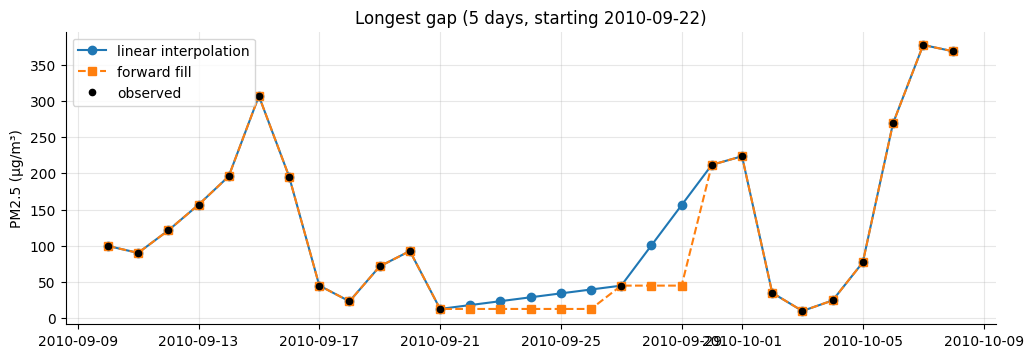

,gap length (days),RMSE interpolation,RMSE forward fill
0,1,53.8,77.1
1,3,71.0,95.2
2,7,84.8,105.4


,observed,interpolated,ffilled
count,1789.0,1826.0,1825.0
mean,98.7,98.6,98.1
std,77.6,77.1,77.2
min,3.0,3.0,3.0
25%,42.2,42.4,41.7
50%,79.2,79.6,78.9
75%,131.2,131.1,130.7
max,552.5,552.5,552.5


Remaining NaN after cleaning: {'pm2.5': 1, 'DEWP': 0, 'TEMP': 0, 'PRES': 0, 'Iws': 0, 'Is': 0, 'Ir': 0, 'cbwd': 0} (only day 1 has nothing to copy from)


In [4]:
# A1: interpolation vs forward fill, then build the cleaned series used for the rest of the notebook
pm_raw = daily["pm2.5"]
print("NaN in the other columns:", daily.drop(columns="pm2.5").isna().sum().to_dict())

# --- how are the missing days distributed? (lengths of consecutive NaN runs)
isna = pm_raw.isna()
run_id = (isna != isna.shift()).cumsum()
runs = isna.groupby(run_id).agg(["first", "sum"])
gaps = runs[runs["first"]]["sum"].astype(int)
print(f"{isna.sum()} missing days in {len(gaps)} gaps | longest gaps (days): {sorted(gaps.tolist(), reverse=True)[:8]}")

pm_interp = pm_raw.interpolate(method="linear", limit_direction="both")   # uses the value AFTER the gap (future!)
pm_ffill = pm_raw.ffill()                                                  # uses only past values (causal)

# --- plot both strategies around the longest gap
gap_days = pm_raw.index[run_id == gaps.idxmax()]
lo, hi = gap_days[0] - pd.Timedelta(days=12), gap_days[-1] + pd.Timedelta(days=12)
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(pm_interp[lo:hi], "o-", color="tab:blue", label="linear interpolation")
ax.plot(pm_ffill[lo:hi], "s--", color="tab:orange", label="forward fill")
ax.plot(pm_raw[lo:hi], "k.", ms=9, label="observed")
ax.set_title(f"Longest gap ({gaps.max()} days, starting {gap_days[0].date()})"); ax.set_ylabel("PM2.5 (µg/m³)"); ax.legend()
plt.show()

# --- artificial-gap experiment: hide known values, fill them both ways, measure the error
vals = pm_raw.values
rng = np.random.default_rng(SEED)
rows = []
for L in (1, 3, 7):
    ei, ef = [], []
    for s in rng.permutation(np.arange(1, len(vals) - L - 1)):
        blk, left, right = vals[s:s + L], vals[s - 1], vals[s + L]
        if np.isnan(blk).any() or np.isnan(left) or np.isnan(right):
            continue
        ei.append(left + (right - left) * np.arange(1, L + 1) / (L + 1) - blk)   # interpolation error
        ef.append(np.full(L, left) - blk)                                         # forward-fill error
        if len(ei) >= 300:
            break
    ei, ef = np.concatenate(ei), np.concatenate(ef)
    rows.append({"gap length (days)": L, "RMSE interpolation": np.sqrt((ei ** 2).mean()),
                 "RMSE forward fill": np.sqrt((ef ** 2).mean())})
gap_table = pd.DataFrame(rows).round(1)
display(gap_table)
display(pd.DataFrame({"observed": pm_raw, "interpolated": pm_interp, "ffilled": pm_ffill}).describe().round(1))

# --- keep forward fill: it is causal (a value at day t never depends on anything after t)
daily_clean = daily.copy()
daily_clean["pm2.5"] = pm_ffill
other_cols = [c for c in daily.columns if c != "pm2.5"]
daily_clean[other_cols] = daily_clean[other_cols].ffill()
print("Remaining NaN after cleaning:", daily_clean.isna().sum().to_dict(), "(only day 1 has nothing to copy from)")

**A1 — Your answer:**

*Write 3–6 sentences here, quoting the numbers your code produced.*

### A2 (2 marks)
Plot daily PM2.5 for 2010–2014 with a 30-day rolling mean. Then plot its histogram and that of `log1p(PM2.5)`. Report the skewness of both and decide whether to model the **raw** or the **log** target. State how this choice will change the *units* of every SHAP value you report later.

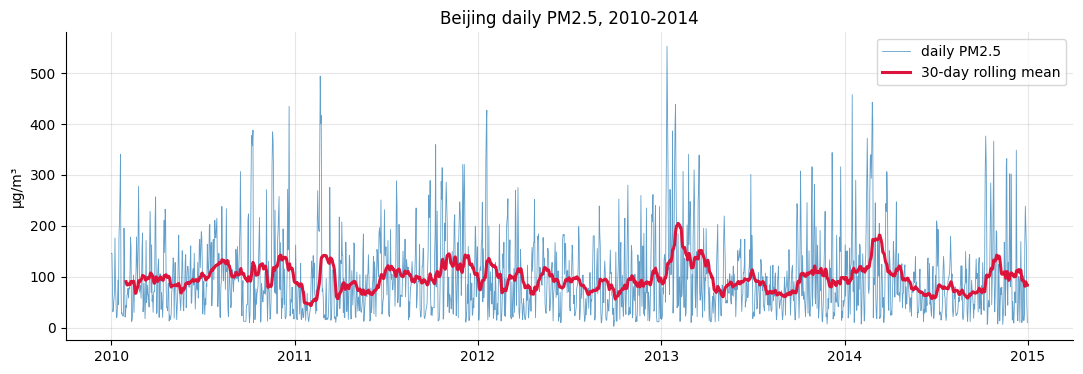

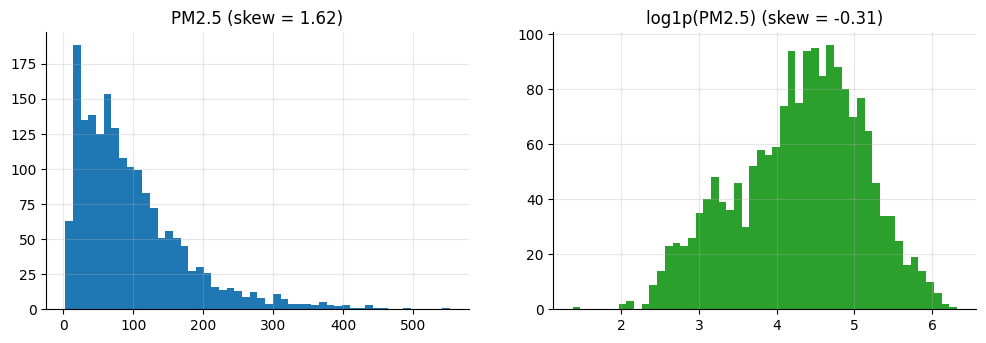

Skewness raw = 1.62 | log1p = -0.31
USE_LOG_TARGET = True -> SHAP values will be in log1p(µg/m³) units


In [5]:
# A2: time plot, rolling mean, histograms, skewness
pm_expl = daily_clean["pm2.5"].bfill()          # exploration only: day 1 has no earlier value to copy

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(pm_expl, lw=0.6, alpha=0.7, label="daily PM2.5")
ax.plot(pm_expl.rolling(30).mean(), lw=2.2, color="crimson", label="30-day rolling mean")
ax.set_ylabel("µg/m³"); ax.set_title("Beijing daily PM2.5, 2010-2014"); ax.legend()
plt.show()

skew_raw, skew_log = pm_expl.skew(), np.log1p(pm_expl).skew()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].hist(pm_expl, bins=50, color="tab:blue"); axes[0].set_title(f"PM2.5 (skew = {skew_raw:.2f})")
axes[1].hist(np.log1p(pm_expl), bins=50, color="tab:green"); axes[1].set_title(f"log1p(PM2.5) (skew = {skew_log:.2f})")
plt.show()
print(f"Skewness raw = {skew_raw:.2f} | log1p = {skew_log:.2f}")

USE_LOG_TARGET = bool(abs(skew_log) < abs(skew_raw))   # model whichever target is closer to symmetric
print("USE_LOG_TARGET =", USE_LOG_TARGET, "-> SHAP values will be in", "log1p(µg/m³) units" if USE_LOG_TARGET else "µg/m³")

**A2 — Your answer:**

*Write 3–6 sentences here, quoting the numbers your code produced.*

### A3 (3 marks)
Run an STL decomposition (period 365) on your chosen target. Report the share of variance in the seasonal and residual components. Compare with the temperature series from the lecture (66.9% seasonal): is pollution more or less predictable from the calendar alone? Explain why physically.

Share of variance of the target (%):
trend        0.4
seasonal    61.7
residual    73.0
(components are correlated, so the three shares need not add to 100 %; normalised: {'trend': 0.3, 'seasonal': 45.6, 'residual': 54.1} )
Temperature in the lecture: 66.9 % seasonal


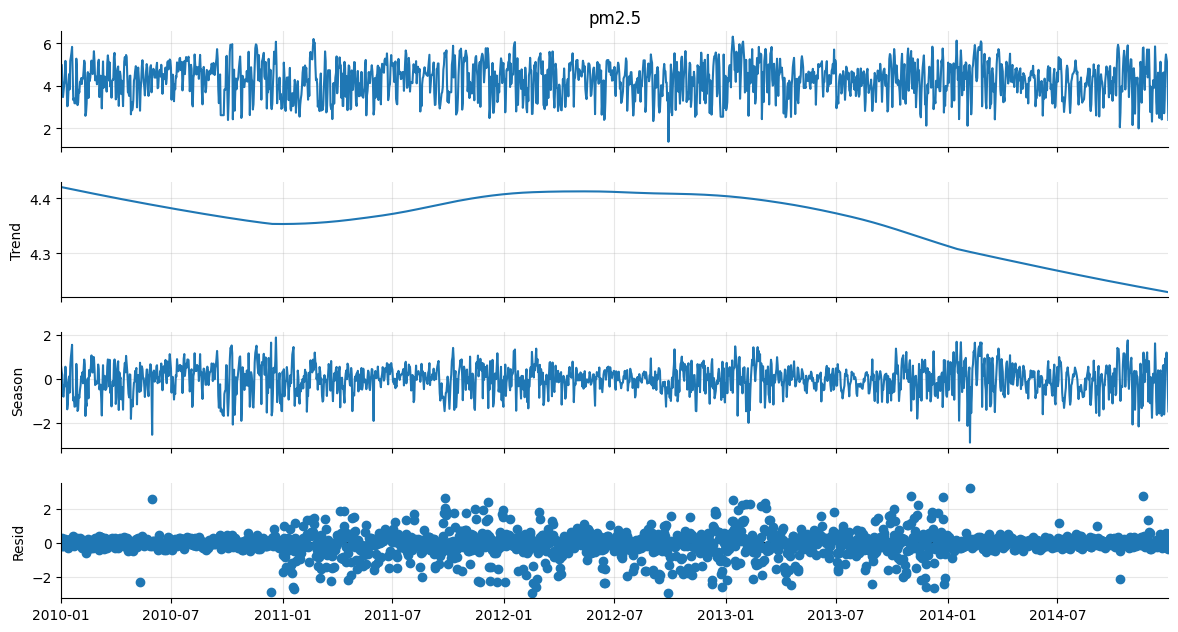

In [6]:
# A3: STL decomposition (period 365) of the chosen target
y_expl = np.log1p(pm_expl) if USE_LOG_TARGET else pm_expl
stl = STL(y_expl, period=365, robust=True).fit()
var_y = y_expl.var()
stl_share = pd.Series({"trend": stl.trend.var() / var_y, "seasonal": stl.seasonal.var() / var_y,
                       "residual": stl.resid.var() / var_y})
print("Share of variance of the target (%):")
print((stl_share * 100).round(1).to_string())
print("(components are correlated, so the three shares need not add to 100 %; normalised:",
      (stl_share / stl_share.sum() * 100).round(1).to_dict(), ")")
print("Temperature in the lecture: 66.9 % seasonal")
fig = stl.plot(); fig.set_size_inches(12, 7); plt.show()

**A3 — Your answer:**

*Write 3–6 sentences here, quoting the numbers your code produced.*

### A4 (3 marks)
1. Plot the ACF and PACF of the target up to lag 30.
2. Compute the Spearman correlation between **tomorrow's** PM2.5 and **today's** value of each weather variable (`DEWP`, `TEMP`, `PRES`, `Iws`, `Is`, `Ir`).
3. Show the mean next-day PM2.5 by today's wind direction (`cbwd`).

From these results, write down your **sanity prior**: a ranked list of the 4–5 inputs you expect a faithful explanation to put at the top, with the expected sign (+ / −) of each.

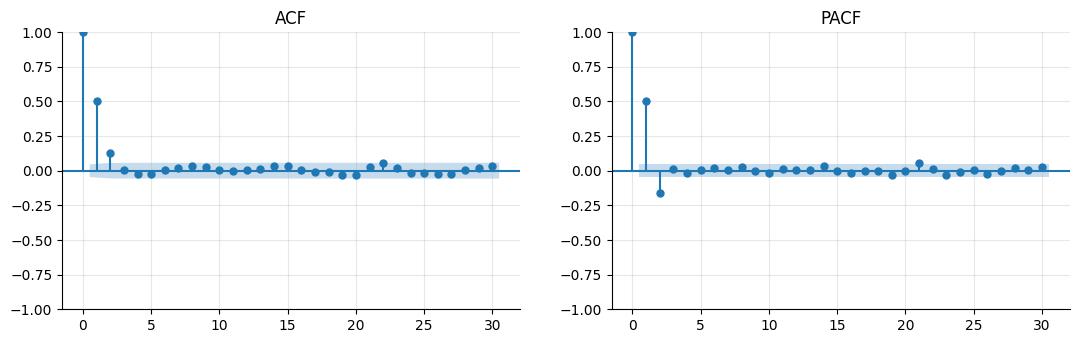

In [7]:
# A4.1: ACF / PACF of the target up to lag 30
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
plot_acf(y_expl, lags=30, ax=ax[0]); ax[0].set_title("ACF")
plot_pacf(y_expl, lags=30, ax=ax[1], method="ywm"); ax[1].set_title("PACF")
plt.show()

Spearman(today's variable, tomorrow's PM2.5):
PM2.5 today (persistence)    0.499
Iws                         -0.369
Ir                          -0.129
DEWP                         0.109
Is                           0.035
PRES                         0.021
TEMP                        -0.001


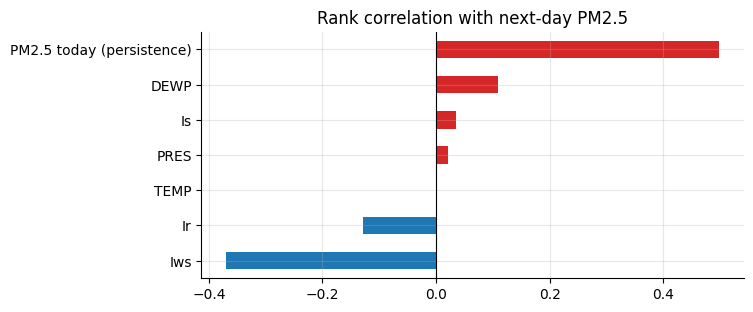


Mean next-day PM2.5 by today's wind direction:


,mean,median,count
wind today,,,
NE,70.9,53.5,95
NW,73.4,49.5,711
SE,109.3,97.9,801
cv,149.0,121.2,218


In [8]:
# A4.2 and A4.3: correlations with NEXT-day PM2.5 and mean next-day PM2.5 by today's wind direction
nxt = pm_expl.shift(-1)                      # tomorrow's PM2.5 aligned with today's row
weather = ["DEWP", "TEMP", "PRES", "Iws", "Is", "Ir"]
corr = pd.Series({c: spearmanr(daily_clean[c], nxt, nan_policy="omit")[0] for c in weather})
corr["PM2.5 today (persistence)"] = spearmanr(pm_expl, nxt, nan_policy="omit")[0]
corr = corr.sort_values(key=abs, ascending=False)
print("Spearman(today's variable, tomorrow's PM2.5):")
print(corr.round(3).to_string())
corr.sort_values().plot.barh(color=["tab:red" if v > 0 else "tab:blue" for v in corr.sort_values()], figsize=(7, 3.2))
plt.axvline(0, color="k", lw=0.8); plt.title("Rank correlation with next-day PM2.5"); plt.show()

wind = (pd.DataFrame({"wind today": daily_clean["cbwd"], "next-day PM2.5": nxt}).dropna()
          .groupby("wind today")["next-day PM2.5"].agg(["mean", "median", "count"]).round(1).sort_values("mean"))
print("\nMean next-day PM2.5 by today's wind direction:")
display(wind)

**A4 — Your sanity prior:**

| Rank | Input | Expected sign | Reason |
|---|---|---|---|
| 1 | | | |
| 2 | | | |
| 3 | | | |
| 4 | | | |
| 5 | | | |

---
# Part B: Feature engineering and forecasters (15 marks)

### B1 (5 marks)
Write `make_features(df) -> pd.DataFrame` that creates, for each day *t*, **only information available at the end of day t − 1**:

| Group | Features to create |
|---|---|
| PM2.5 recent lags | `pm_lag_1` … `pm_lag_3` |
| PM2.5 older lags | `pm_lag_4` … `pm_lag_7` |
| PM2.5 rolling stats | `pm_roll_mean_3`, `pm_roll_mean_7`, `pm_roll_std_7` |
| Weather, yesterday | `DEWP_lag_1`, `TEMP_lag_1`, `PRES_lag_1`, `Iws_lag_1`, `Is_lag_1`, `Ir_lag_1` |
| Weather change | `PRES_diff_1` (= PRES at t−1 minus t−2), `DEWP_diff_1` |
| Wind direction | one-hot of `cbwd` at t − 1 (4 columns) |
| Calendar | `doy_sin`, `doy_cos`, `is_heating_season` (15 Nov – 15 Mar), `dow` |

Store the groups in a dict `FEATURE_GROUPS`. Then write the leakage test: overwrite every raw value on one test day with random numbers, rebuild the features, and `assert` that the feature row for that same day is unchanged.

In [9]:
WEATHER = ["DEWP", "TEMP", "PRES", "Iws", "Is", "Ir"]
WIND_DIRS = ["NW", "NE", "SE", "cv"]

def make_features(df: pd.DataFrame) -> pd.DataFrame:
    X = pd.DataFrame(index=df.index)
    pm = df["pm2.5"]
    # PM2.5 lags 1..7  (value of day t-k)
    for k in range(1, 8):
        X[f"pm_lag_{k}"] = pm.shift(k)
    # rolling stats computed on pm.shift(1): the window ends at day t-1
    past = pm.shift(1)
    X["pm_roll_mean_3"] = past.rolling(3).mean()
    X["pm_roll_mean_7"] = past.rolling(7).mean()
    X["pm_roll_std_7"] = past.rolling(7).std()
    # yesterday's weather, weather changes, one-hot wind direction at t-1
    for c in WEATHER:
        X[f"{c}_lag_1"] = df[c].shift(1)
    X["PRES_diff_1"] = df["PRES"].shift(1) - df["PRES"].shift(2)
    X["DEWP_diff_1"] = df["DEWP"].shift(1) - df["DEWP"].shift(2)
    wd = df["cbwd"].shift(1)
    for d in WIND_DIRS:
        X[f"wd_{d}"] = (wd == d).astype(float).where(wd.notna())
    # calendar features are known in advance, so day t itself is fine
    doy = np.asarray(df.index.dayofyear)
    X["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
    X["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)
    md = np.asarray(df.index.month) * 100 + np.asarray(df.index.day)
    X["is_heating_season"] = ((md >= 1115) | (md <= 315)).astype(int)      # 15 Nov - 15 Mar
    X["dow"] = np.asarray(df.index.dayofweek)
    # Target (transform it if USE_LOG_TARGET)
    X["target"] = np.log1p(pm) if USE_LOG_TARGET else pm
    return X.dropna()

FEATURE_GROUPS = {
    "PM recent lags (1-3)": ["pm_lag_1", "pm_lag_2", "pm_lag_3"],
    "PM older lags (4-7)":  ["pm_lag_4", "pm_lag_5", "pm_lag_6", "pm_lag_7"],
    "PM rolling stats":     ["pm_roll_mean_3", "pm_roll_mean_7", "pm_roll_std_7"],
    "Weather yesterday":    [f"{c}_lag_1" for c in WEATHER],
    "Weather change":       ["PRES_diff_1", "DEWP_diff_1"],
    "Wind direction":       [f"wd_{d}" for d in WIND_DIRS],
    "Calendar":             ["doy_sin", "doy_cos", "is_heating_season", "dow"],
}

data = make_features(daily_clean)
feature_names = [c for c in data.columns if c != "target"]
assert sorted(sum(FEATURE_GROUPS.values(), [])) == sorted(feature_names), "groups must partition the features"
print(f"{len(data)} samples x {len(feature_names)} features")

1818 samples x 26 features


In [10]:
# B1 leakage test: corrupt every raw value of one test day, rebuild, and compare that day's feature row
test_day = pd.Timestamp("2014-06-15")
rng_leak = np.random.default_rng(SEED)
num_cols = ["pm2.5", "DEWP", "TEMP", "PRES", "Iws", "Is", "Ir"]
corrupted = daily_clean.copy().astype({c: float for c in num_cols})   # floats can be written into int columns (Is, Ir)
corrupted.loc[test_day, num_cols] = rng_leak.uniform(1, 500, len(num_cols))
corrupted.loc[test_day, "cbwd"] = rng_leak.choice(WIND_DIRS)
feat_c = make_features(corrupted)
assert feat_c.loc[test_day, feature_names].equals(data.loc[test_day, feature_names]), "LEAKAGE: day t features changed!"
# the test is not vacuous: the NEXT day must see the corruption
next_day = test_day + pd.Timedelta(days=1)
assert not feat_c.loc[next_day, feature_names].equals(data.loc[next_day, feature_names])
print("Leakage test passed")

Leakage test passed


### B2 (2 marks)
Apply the fixed split. Print the date range and number of rows of train, validation and test.

In [11]:
# B2: fixed chronological split
train = data.loc["2010":"2012"]
val = data.loc["2013"]
test = data.loc["2014"]
for name, d in (("train", train), ("val", val), ("test", test)):
    print(f"{name:5s} {d.index.min().date()} -> {d.index.max().date()} | {len(d):4d} rows")

X_train, y_train = train[feature_names], train["target"]
X_val, y_val = val[feature_names], val["target"]
X_test, y_test = test[feature_names], test["target"]

# helper: back to µg/m³ (all reported errors are in µg/m³)
inv = (lambda z: np.clip(np.expm1(z), 0, None)) if USE_LOG_TARGET else (lambda z: np.clip(z, 0, None))
y_test_raw = daily_clean.loc[test.index, "pm2.5"]          # true test values in µg/m³

train 2010-01-09 -> 2012-12-31 | 1088 rows
val   2013-01-01 -> 2013-12-31 |  365 rows
test  2014-01-01 -> 2014-12-31 |  365 rows


### B3 (4 marks)
Fit and report test **MAE and RMSE in µg/m³** (even if you model the log target) for:
- (a) persistence: tomorrow = today,
- (b) 7-day mean,
- (c) a LightGBM regressor with early stopping on 2013.

Present the results in one table.

In [12]:
lgbm = lgb.LGBMRegressor(n_estimators=2000, learning_rate=0.02, random_state=SEED, verbose=-1)
lgbm.fit(X_train, y_train, eval_set=[(X_val, y_val)], callbacks=[lgb.early_stopping(100, verbose=False)])
print("LightGBM best iteration:", lgbm.best_iteration_)
pred_test = inv(lgbm.predict(X_test))                      # µg/m³

results = pd.DataFrame({
    "Persistence": metrics(y_test_raw, test["pm_lag_1"]),          # tomorrow = today
    "7-day mean":  metrics(y_test_raw, test["pm_roll_mean_7"]),    # mean of the last 7 days
    "LightGBM":    metrics(y_test_raw, pred_test),
}).T.round(2)
results

LightGBM best iteration: 123


,MAE,RMSE
Persistence,52.75,75.71
7-day mean,60.59,82.76
LightGBM,45.40,67.14


**B3 — Your answer:**

*Write 3–6 sentences here, quoting the numbers your code produced.*

### B4 (4 marks) — the leakage experiment
Train a second LightGBM, `lgbm_oracle`, that additionally receives **day t's** weather (`DEWP`, `PRES`, `Iws`, `cbwd` at *t*). This simulates having a perfect weather forecast. Report its test MAE. In 3–4 sentences, explain when using such features is legitimate in a real system and when it is leakage. You will explain both models in Part C.

In [13]:
# B4: oracle model that also sees day t's weather (simulates a perfect weather forecast)
ORACLE_EXTRA = ["DEWP_t", "PRES_t", "Iws_t"] + [f"wd_{d}_t" for d in WIND_DIRS]

def add_oracle(base):
    out = base.copy()
    for c in ["DEWP", "PRES", "Iws"]:
        out[f"{c}_t"] = daily_clean.loc[base.index, c].values
    for d in WIND_DIRS:
        out[f"wd_{d}_t"] = (daily_clean.loc[base.index, "cbwd"] == d).astype(float).values
    return out

X_train_or, X_val_or, X_test_or = add_oracle(X_train), add_oracle(X_val), add_oracle(X_test)
oracle_features = list(X_train_or.columns)

lgbm_oracle = lgb.LGBMRegressor(n_estimators=2000, learning_rate=0.02, random_state=SEED, verbose=-1)
lgbm_oracle.fit(X_train_or, y_train, eval_set=[(X_val_or, y_val)], callbacks=[lgb.early_stopping(100, verbose=False)])
pred_test_or = inv(lgbm_oracle.predict(X_test_or))
results.loc["LightGBM oracle (day-t weather)"] = pd.Series(metrics(y_test_raw, pred_test_or)).round(2)
print(f"Oracle best iteration: {lgbm_oracle.best_iteration_} | test MAE {results.loc['LightGBM oracle (day-t weather)', 'MAE']:.2f} µg/m³")
results

Oracle best iteration: 886 | test MAE 30.35 µg/m³


,MAE,RMSE
Persistence,52.75,75.71
7-day mean,60.59,82.76
LightGBM,45.40,67.14
LightGBM oracle (day-t weather),30.35,43.31


**B4 — Your answer:**

*Write 3–6 sentences here, quoting the numbers your code produced.*

---
# Part C: SHAP (25 marks)
Use `shap.TreeExplainer` on the LightGBM from B3 unless told otherwise. If you model the log target, state clearly that SHAP values are in log units.

### C1 (3 marks)
Compute SHAP values for the 2014 test set. Verify the **efficiency** property numerically: report the maximum absolute gap between base value + Σφ and the model output. Report the base value and translate it into µg/m³.

In [14]:
# C1: SHAP values for the 2014 test set + efficiency check
tree_explainer = shap.TreeExplainer(lgbm)
shap_exp = tree_explainer(X_test)

model_out = lgbm.predict(X_test)                                   # model output (log units if USE_LOG_TARGET)
recon = shap_exp.base_values + shap_exp.values.sum(axis=1)         # base value + sum of SHAP values
max_gap = np.abs(recon - model_out).max()
base_val = float(np.ravel(tree_explainer.expected_value)[0])
unit = "log1p(µg/m³)" if USE_LOG_TARGET else "µg/m³"
print(f"SHAP values are in {unit}")
print(f"Efficiency: max |base + sum(phi) - model output| = {max_gap:.2e}")
print(f"Base value = {base_val:.4f} {unit}  ->  {inv(base_val):.1f} µg/m³")
print(f"(back-transformed mean of the training target = {inv(y_train.mean()):.1f} µg/m³, the arithmetic mean of raw PM2.5 in the training years = {daily_clean.loc[train.index,'pm2.5'].mean():.1f} µg/m³)")

SHAP values are in log1p(µg/m³)
Efficiency: max |base + sum(phi) - model output| = 1.07e-14
Base value = 4.2856 log1p(µg/m³)  ->  71.6 µg/m³
(back-transformed mean of the training target = 71.6 µg/m³, the arithmetic mean of raw PM2.5 in the training years = 97.0 µg/m³)


**C1 — Your answer:**

*Write 3–6 sentences here, quoting the numbers your code produced.*

### C2 (5 marks)
Produce the global **bar** plot and **beeswarm** plot. Compare the top five features with your sanity prior from A4. For each weather feature in the top ten, state whether its colour pattern (direction) matches the physics in the domain hints. Identify one feature whose effect is *conditional*, like `lag_2` in the lecture, and explain it.

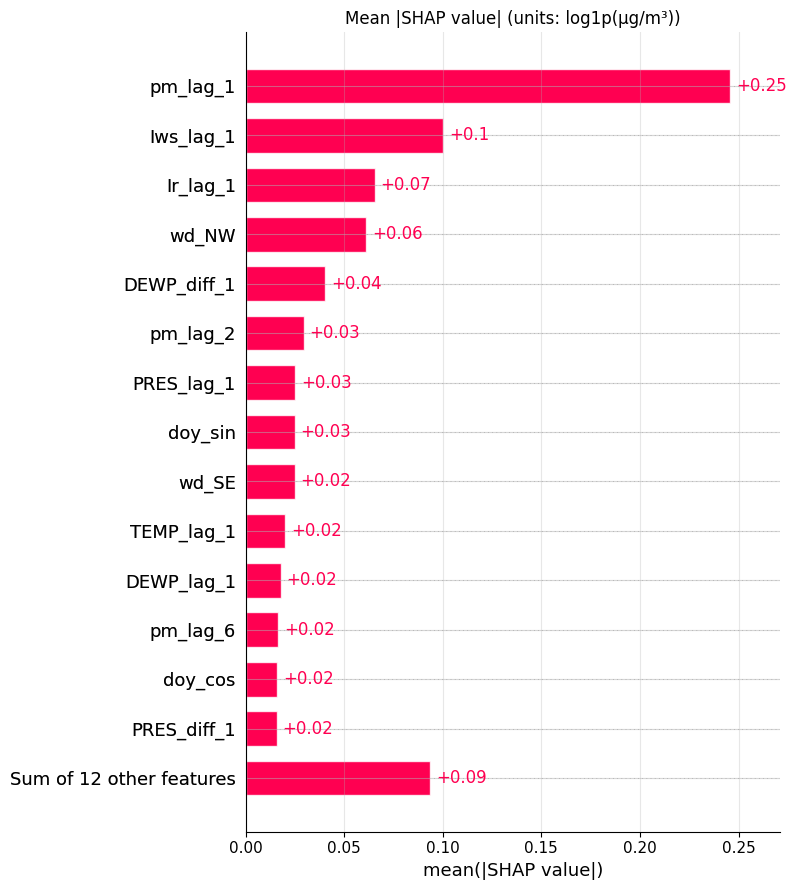

Top-10 features by mean |SHAP|:
pm_lag_1       0.2458
Iws_lag_1      0.1003
Ir_lag_1       0.0655
wd_NW          0.0612
DEWP_diff_1    0.0405
pm_lag_2       0.0296
PRES_lag_1     0.0253
doy_sin        0.0250
wd_SE          0.0249
TEMP_lag_1     0.0202


In [15]:
# C2: global bar plot
shap.plots.bar(shap_exp, max_display=15, show=False)
plt.title(f"Mean |SHAP value| (units: {unit})"); plt.tight_layout(); plt.show()
top = pd.Series(np.abs(shap_exp.values).mean(0), index=feature_names).sort_values(ascending=False)
print("Top-10 features by mean |SHAP|:"); print(top.head(10).round(4).to_string())

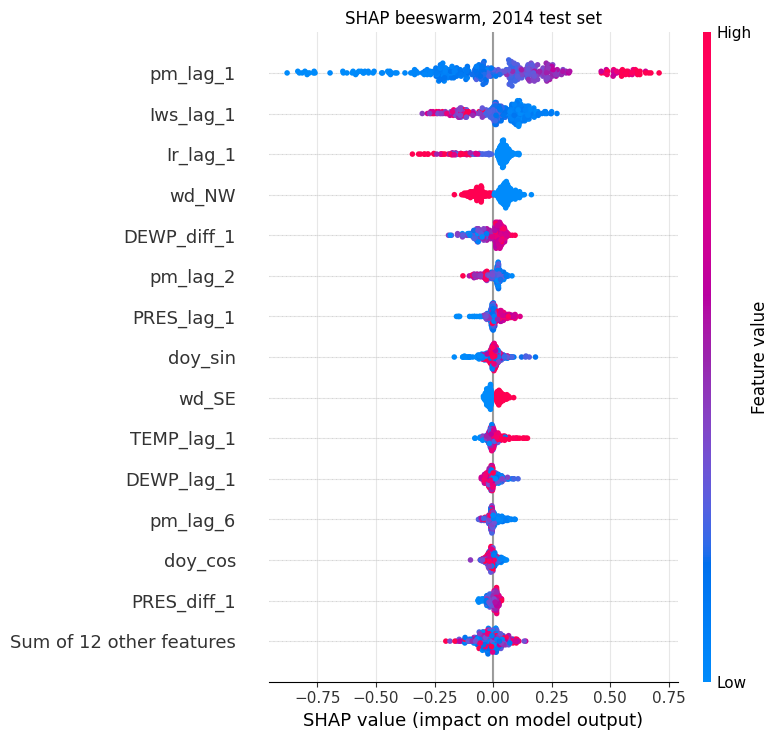

In [16]:
# C2: beeswarm plot
shap.plots.beeswarm(shap_exp, max_display=15, show=False)
plt.title("SHAP beeswarm, 2014 test set"); plt.tight_layout(); plt.show()

**C2 — Your answer:**

*Write 3–6 sentences here, quoting the numbers your code produced.*

### C3 (5 marks)
Choose three test days:
1. the most polluted **forecast**,
2. the day with the largest absolute **error**,
3. the day with the largest one-day **drop** in actual PM2.5 (a clean-air event).

Draw a waterfall plot for each. For the clean-air day: did the model anticipate the drop, and which inputs pushed it down? If it missed, what information was it lacking?

,date,forecast,actual,yesterday actual,abs error
most polluted forecast,2014-10-11,238.2,197.6,325.4,40.7
largest abs error,2014-01-16,151.6,457.5,191.8,305.9
largest one-day drop,2014-02-27,115.5,19.9,407.7,95.6



=== most polluted forecast: 2014-10-11 (SHAP values in log1p(µg/m³)) ===


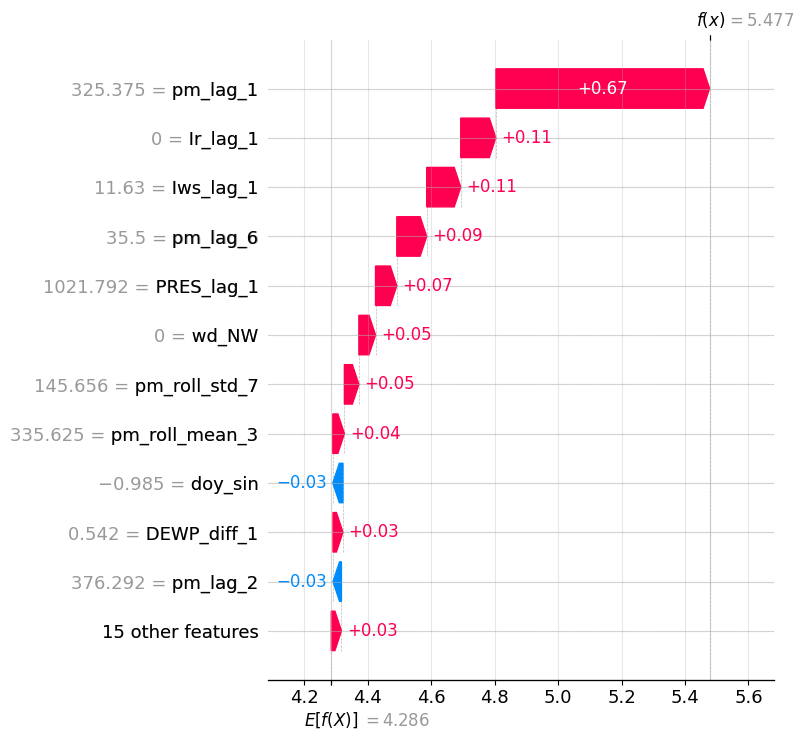


=== largest abs error: 2014-01-16 (SHAP values in log1p(µg/m³)) ===


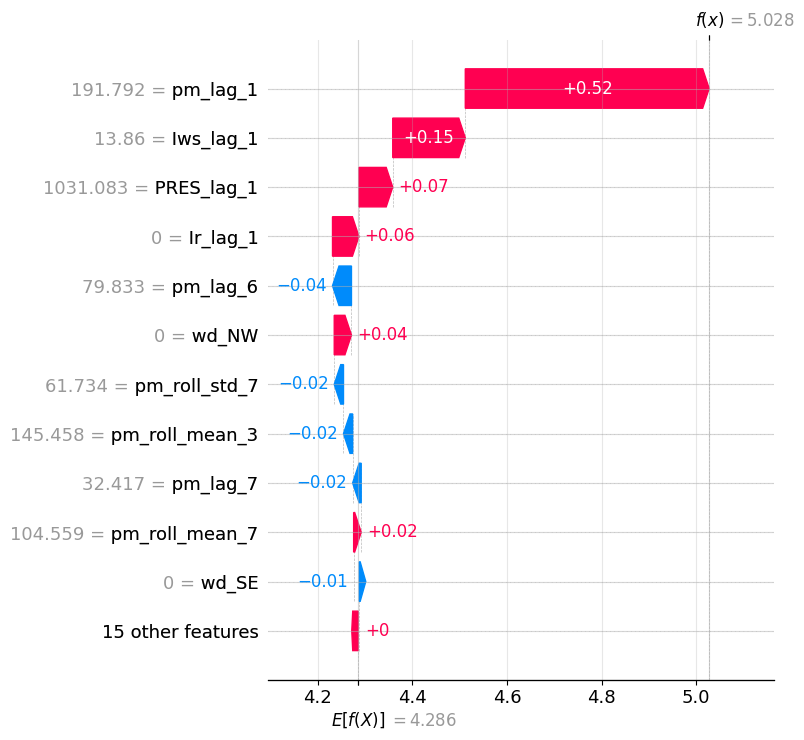


=== largest one-day drop: 2014-02-27 (SHAP values in log1p(µg/m³)) ===


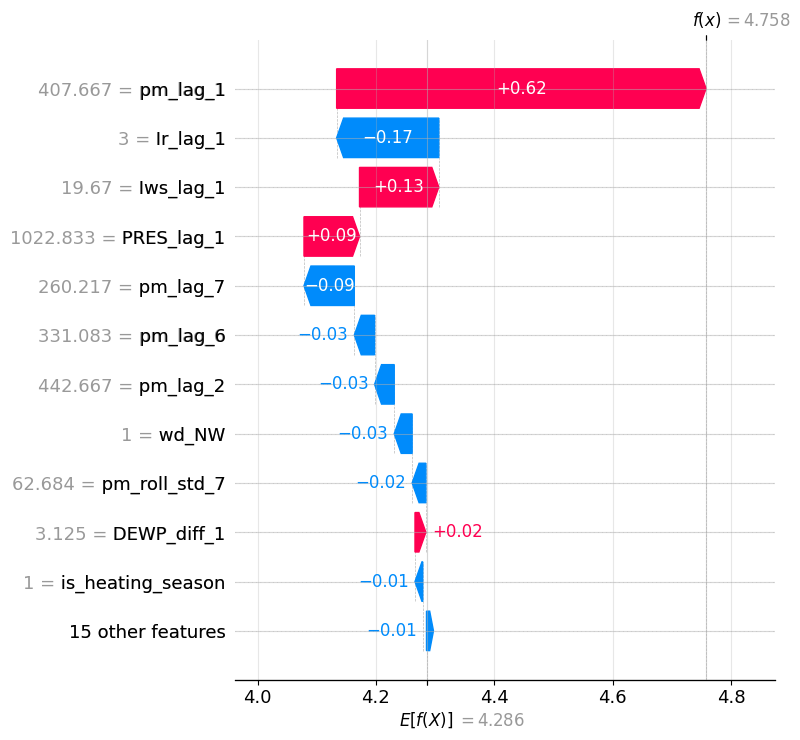

In [17]:
# C3: three test days
pred_s = pd.Series(pred_test, index=test.index)         # forecast in µg/m³
actual = y_test_raw
abs_err = (actual - pred_s).abs()
drop = actual - test["pm_lag_1"]                         # today's actual minus yesterday's actual

idx_high = pred_s.idxmax()       # most polluted forecast
idx_err = abs_err.idxmax()       # largest absolute error
idx_drop = drop.idxmin()         # largest one-day drop in actual PM2.5 (clean-air event)

picked = {"most polluted forecast": idx_high, "largest abs error": idx_err, "largest one-day drop": idx_drop}
summary = pd.DataFrame({
    name: {"date": d.date(), "forecast": round(pred_s[d], 1), "actual": round(actual[d], 1),
           "yesterday actual": round(test.loc[d, "pm_lag_1"], 1), "abs error": round(abs_err[d], 1)}
    for name, d in picked.items()}).T
display(summary)

for name, d in picked.items():
    print(f"\n=== {name}: {d.date()} (SHAP values in {unit}) ===")
    shap.plots.waterfall(shap_exp[test.index.get_loc(d)], max_display=12, show=False)
    plt.tight_layout(); plt.show()

**C3 — Your answer:**

*Write 3–6 sentences here, quoting the numbers your code produced.*

### C4 (4 marks)
Draw two dependence plots: `Iws_lag_1` coloured by the NW wind indicator, and `pm_lag_1` coloured by `DEWP_lag_1`. Describe the shape of each learned response curve (linear, saturating, threshold) and the interaction the colour reveals.

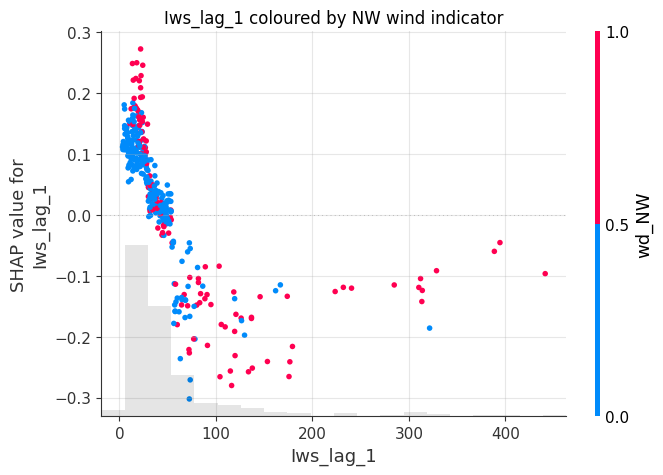

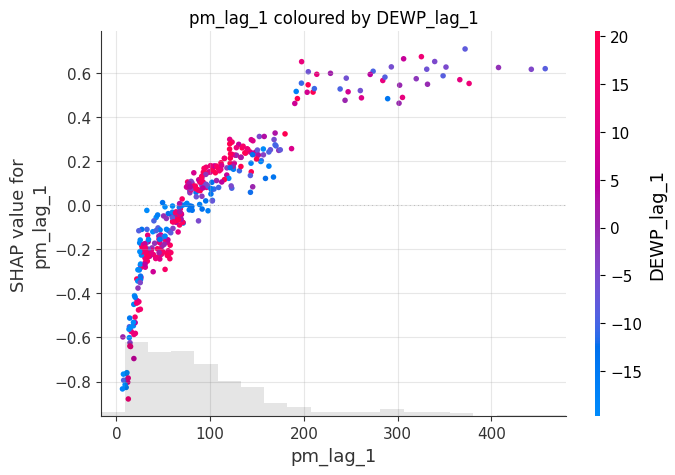

Mean SHAP(Iws_lag_1): NW days = -0.009 | other days = +0.043
Mean SHAP(pm_lag_1): humid days = -0.000 | dry days = +0.010


In [18]:
# C4: dependence plots
shap.plots.scatter(shap_exp[:, "Iws_lag_1"], color=shap_exp[:, "wd_NW"], show=False)
plt.title("Iws_lag_1 coloured by NW wind indicator"); plt.show()

shap.plots.scatter(shap_exp[:, "pm_lag_1"], color=shap_exp[:, "DEWP_lag_1"], show=False)
plt.title("pm_lag_1 coloured by DEWP_lag_1"); plt.show()

# numbers to quote: mean SHAP of Iws_lag_1 for NW vs non-NW days, and pm_lag_1 for humid vs dry days
i_iws, i_nw = feature_names.index("Iws_lag_1"), feature_names.index("wd_NW")
nw = X_test["wd_NW"].values == 1
print(f"Mean SHAP(Iws_lag_1): NW days = {shap_exp.values[nw, i_iws].mean():+.3f} | other days = {shap_exp.values[~nw, i_iws].mean():+.3f}")
i_pm = feature_names.index("pm_lag_1")
humid = X_test["DEWP_lag_1"].values > X_test["DEWP_lag_1"].median()
print(f"Mean SHAP(pm_lag_1): humid days = {shap_exp.values[humid, i_pm].mean():+.3f} | dry days = {shap_exp.values[~humid, i_pm].mean():+.3f}")

**C4 — Your answer:**

*Write 3–6 sentences here, quoting the numbers your code produced.*

### C5 (5 marks) — grouped and seasonal SHAP
Sum SHAP values within each group of `FEATURE_GROUPS`. Plot:
- (a) mean |grouped SHAP| as a bar chart,
- (b) a month × group heatmap of mean |grouped SHAP| for 2014.

Is the model mainly a persistence model or a weather model? Does reliance on weather change between the heating and non-heating seasons?

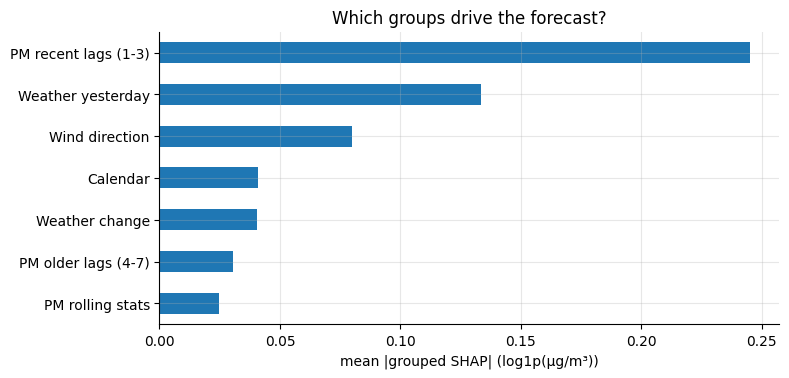

PM recent lags (1-3)    41.2
Weather yesterday       22.5
Wind direction          13.5
Calendar                 6.8
Weather change           6.8
PM older lags (4-7)      5.1
PM rolling stats         4.1 
(% of total)


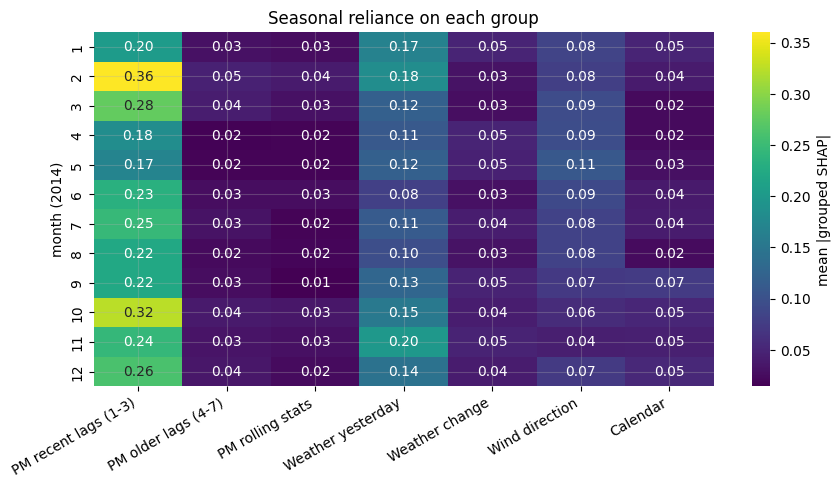

,non-heating,heating,heating / non-heating
PM recent lags (1-3),0.236,0.264,1.120
PM older lags (4-7),0.027,0.038,1.426
PM rolling stats,0.022,0.029,1.288
Weather yesterday,0.117,0.168,1.439
Weather change,0.040,0.040,1.000
Wind direction,0.083,0.075,0.910
Calendar,0.039,0.045,1.152


In [19]:
# C5: grouped and seasonal SHAP
def grouped_shap(values, columns, index, groups=FEATURE_GROUPS):
    cols = list(columns)
    return pd.DataFrame({g: values[:, [cols.index(f) for f in fs]].sum(axis=1) for g, fs in groups.items()}, index=index)

group_shap = grouped_shap(shap_exp.values, feature_names, test.index)
assert np.allclose(group_shap.sum(axis=1) + shap_exp.base_values, model_out, atol=1e-6)   # groups still add up

# (a) mean |grouped SHAP|
mean_abs_group = group_shap.abs().mean().sort_values()
mean_abs_group.plot.barh(color="tab:blue", figsize=(8, 3.8))
plt.xlabel(f"mean |grouped SHAP| ({unit})"); plt.title("Which groups drive the forecast?"); plt.show()
print((mean_abs_group[::-1] / mean_abs_group.sum() * 100).round(1).to_string(), "\n(% of total)")

# (b) month x group heatmap
heat = group_shap.abs().groupby(group_shap.index.month).mean()
plt.figure(figsize=(10, 4.6))
sns.heatmap(heat, annot=True, fmt=".2f", cmap="viridis", cbar_kws={"label": "mean |grouped SHAP|"})
plt.xticks(rotation=30, ha="right"); plt.ylabel("month (2014)"); plt.title("Seasonal reliance on each group"); plt.show()

# heating vs non-heating season
season = group_shap.abs().groupby(test["is_heating_season"].values).mean().T
season.columns = ["non-heating", "heating"]
season["heating / non-heating"] = season["heating"] / season["non-heating"]
display(season.round(3))

**C5 — Your answer:**

*Write 3–6 sentences here, quoting the numbers your code produced.*

### C6 (3 marks) — explaining the oracle
Repeat C5(a) for `lgbm_oracle` from B4. How does the importance of the PM2.5 lags change when the model can see day *t*'s weather? Explain what this shows about how correlated inputs share credit.

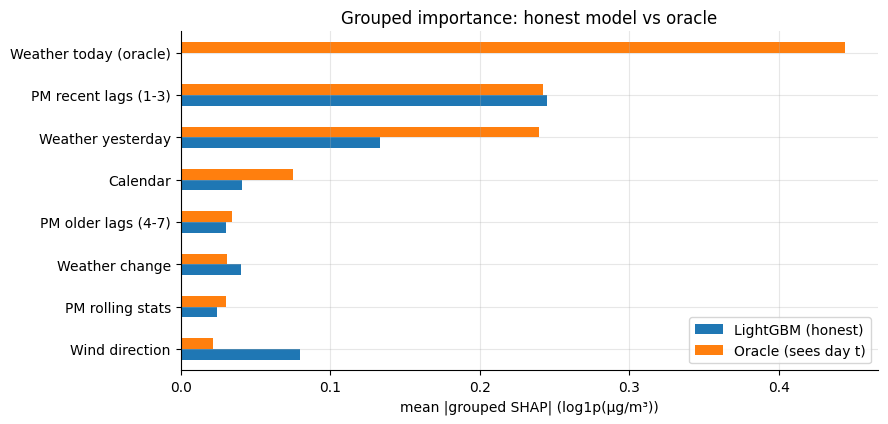

,LightGBM (honest),Oracle (sees day t)
Calendar,0.041,0.075
PM older lags (4-7),0.030,0.034
PM recent lags (1-3),0.245,0.242
PM rolling stats,0.025,0.031
Weather change,0.040,0.031
Weather today (oracle),0.000,0.444
Weather yesterday,0.134,0.240
Wind direction,0.080,0.022


Total PM-history importance: honest = 0.300 -> oracle = 0.307
Share of PM-history in total importance: honest = 50.4% -> oracle = 27.4%


In [20]:
# C6: explain the oracle (it also sees day t's weather)
tree_or = shap.TreeExplainer(lgbm_oracle)
shap_or = tree_or(X_test_or)
groups_or = {**FEATURE_GROUPS, "Weather today (oracle)": ORACLE_EXTRA}
group_shap_or = grouped_shap(shap_or.values, oracle_features, test.index, groups_or)

cmp = pd.DataFrame({"LightGBM (honest)": group_shap.abs().mean(), "Oracle (sees day t)": group_shap_or.abs().mean()}).fillna(0)
cmp.sort_values("Oracle (sees day t)").plot.barh(figsize=(9, 4.4))
plt.xlabel(f"mean |grouped SHAP| ({unit})"); plt.title("Grouped importance: honest model vs oracle"); plt.show()
display(cmp.round(3))
pm_groups = ["PM recent lags (1-3)", "PM older lags (4-7)", "PM rolling stats"]
print(f"Total PM-history importance: honest = {cmp.loc[pm_groups, 'LightGBM (honest)'].sum():.3f} -> oracle = {cmp.loc[pm_groups, 'Oracle (sees day t)'].sum():.3f}")
print(f"Share of PM-history in total importance: honest = {cmp.loc[pm_groups, 'LightGBM (honest)'].sum() / cmp['LightGBM (honest)'].sum():.1%} -> oracle = {cmp.loc[pm_groups, 'Oracle (sees day t)'].sum() / cmp['Oracle (sees day t)'].sum():.1%}")

**C6 — Your answer:**

*Write 3–6 sentences here, quoting the numbers your code produced.*

---
# Part D: LIME (15 marks)

In [21]:
def predict_fn(arr):
    return lgbm.predict(pd.DataFrame(arr, columns=feature_names))

### D1 (4 marks)
Explain the most polluted forecast and the clean-air day from C3 with `LimeTabularExplainer` (5,000 samples). Report the black-box forecast, LIME's surrogate prediction and the local R² for each. Which of the two explanations would you trust more, and why?

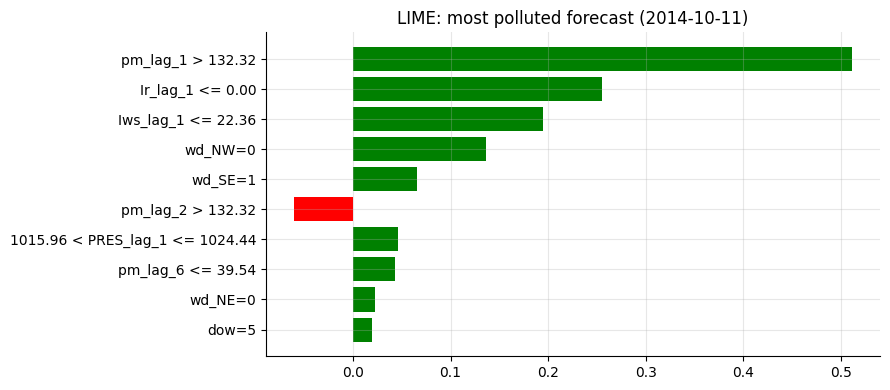

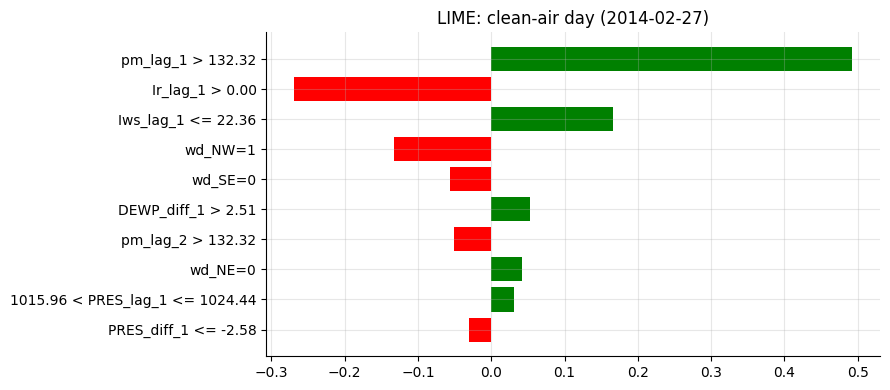

,date,black-box (log1p(µg/m³)),black-box (µg/m³),LIME surrogate (log1p(µg/m³)),surrogate (µg/m³),local R2
most polluted forecast,2014-10-11,5.477,238.2,4.973,143.5,0.49
clean-air day,2014-02-27,4.758,115.5,4.442,83.9,0.478


In [22]:
# D1: LIME on the most polluted forecast and the clean-air day
CAT_IDX = [i for i, c in enumerate(feature_names) if c.startswith("wd_") or c in ("is_heating_season", "dow")]

def make_lime(seed=SEED, discretize=True, categorical=True):
    return LimeTabularExplainer(X_train.values, feature_names=feature_names, mode="regression",
                                categorical_features=CAT_IDX if categorical else None,
                                discretize_continuous=discretize, random_state=seed)

def lime_r2(exp):
    s = exp.score
    return float(list(s.values())[0]) if isinstance(s, dict) else float(s)

def lime_pred(exp):
    p = exp.local_pred
    p = list(p.values())[0] if isinstance(p, dict) else p
    return float(np.ravel(p)[0])

def lime_weight_vector(exp, n_features):
    """weights as an array indexed by feature position (works for regression mode)"""
    key = 1 if 1 in exp.local_exp else list(exp.local_exp)[0]
    w = np.zeros(n_features)
    for i, v in exp.local_exp[key]:
        w[i] = v
    return w

lime_explainer = make_lime()
lime_rows = {}
for name, day in (("most polluted forecast", idx_high), ("clean-air day", idx_drop)):
    x = X_test.values[test.index.get_loc(day)]
    exp = lime_explainer.explain_instance(x, predict_fn, num_features=10, num_samples=5000)
    bb = predict_fn(x.reshape(1, -1))[0]
    lime_rows[name] = {"date": day.date(), f"black-box ({unit})": round(bb, 3), "black-box (µg/m³)": round(float(inv(bb)), 1),
                       f"LIME surrogate ({unit})": round(lime_pred(exp), 3), "surrogate (µg/m³)": round(float(inv(lime_pred(exp))), 1),
                       "local R2": round(lime_r2(exp), 3)}
    fig = exp.as_pyplot_figure(); fig.set_size_inches(9, 4); plt.title(f"LIME: {name} ({day.date()})"); plt.tight_layout(); plt.show()
display(pd.DataFrame(lime_rows).T)

**D1 — Your answer:**

*Write 3–6 sentences here, quoting the numbers your code produced.*

### D2 (4 marks) — unrealistic neighbours
Generate LIME's perturbation samples for one instance (or reproduce LIME's sampling yourself) and count the fraction of neighbours that are **physically implausible**. Define implausible with at least two rules you justify, for example:
- `pm_lag_1` more than 3 × `pm_roll_mean_3` (impossible by construction),
- snow hours > 0 with `TEMP_lag_1` > 10 °C.

Explain why this matters more for time series than for ordinary tabular data.

In [23]:
# D2: how many LIME neighbours are physically implausible?
x0 = X_test.values[test.index.get_loc(idx_high)]
lime_for_samples = make_lime(seed=SEED)
_, neigh = lime_for_samples._LimeTabularExplainer__data_inverse(x0, 5000)   # LIME's perturbation samples, in feature space
S = pd.DataFrame(neigh, columns=feature_names)
wd_cols = [f"wd_{d}" for d in WIND_DIRS]

def implausible(F):
    return pd.DataFrame({
        "pm_lag_1 > 3 x pm_roll_mean_3 (impossible: mean of 3 values >= max/3)": F.pm_lag_1 > 3 * F.pm_roll_mean_3 + 1e-6,
        "7 x pm_roll_mean_7 < lag1+lag2+lag3 (a sub-sum cannot exceed the sum)": 7 * F.pm_roll_mean_7 < F.pm_lag_1 + F.pm_lag_2 + F.pm_lag_3 - 1e-6,
        "snow hours > 0 with TEMP_lag_1 > 10 C": (F.Is_lag_1 > 0) & (F.TEMP_lag_1 > 10),
        "wind one-hot invalid (not exactly one direction)": ~np.isclose(F[wd_cols].sum(axis=1), 1.0),
    })

bad = implausible(S)
bad_real = implausible(X_test)
table = pd.DataFrame({"LIME neighbours (%)": bad.mean() * 100, "real 2014 days (%)": bad_real.mean() * 100})
table.loc["ANY rule violated"] = [bad.any(axis=1).mean() * 100, bad_real.any(axis=1).mean() * 100]
display(table.round(1))
print(f"{bad.any(axis=1).mean():.1%} of the 5000 neighbours violate at least one rule (real data: {bad_real.any(axis=1).mean():.1%}).")

,LIME neighbours (%),real 2014 days (%)
pm_lag_1 > 3 x pm_roll_mean_3 (impossible: mean of 3 values >= max/3),12.9,0.0
7 x pm_roll_mean_7 < lag1+lag2+lag3 (a sub-sum cannot exceed the sum),10.4,0.0
snow hours > 0 with TEMP_lag_1 > 10 C,1.5,0.0
wind one-hot invalid (not exactly one direction),52.0,0.0
ANY rule violated,62.6,0.0


62.6% of the 5000 neighbours violate at least one rule (real data: 0.0%).


**D2 — Your answer:**

*Write 3–6 sentences here, quoting the numbers your code produced.*

### D3 (4 marks) — stability
Re-run LIME 15 times with different seeds, using **500** and **5,000** samples, on the same instance. Show a boxplot of the weights for the top eight features and a table of the coefficient of variation. List the features whose **sign** flips across seeds.

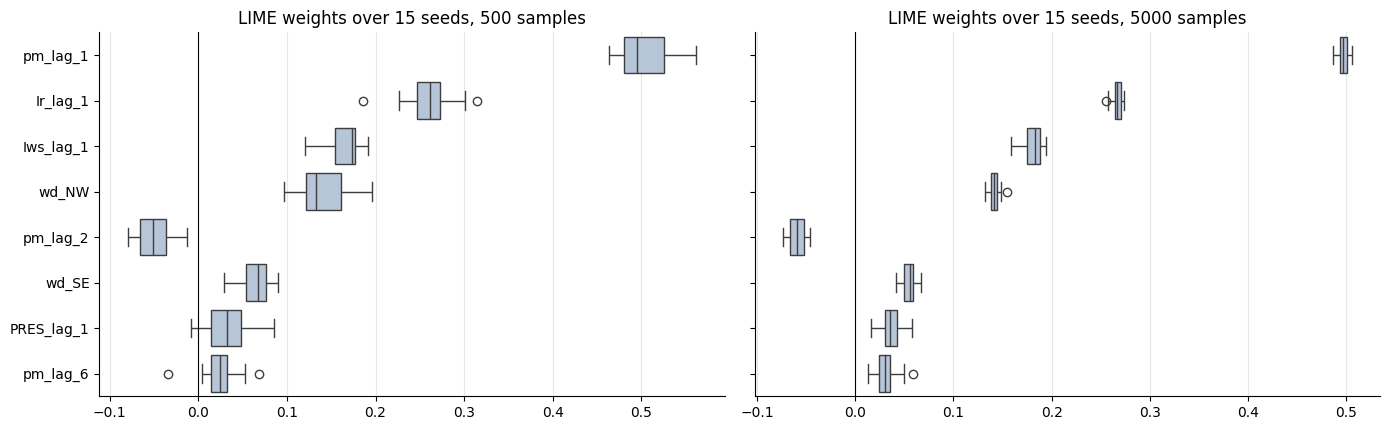

,CV (500),CV (5000)
pm_lag_1,0.06,0.01
Ir_lag_1,0.12,0.02
Iws_lag_1,0.12,0.05
wd_NW,0.20,0.04
pm_lag_2,0.42,0.14
wd_SE,0.26,0.12
PRES_lag_1,0.81,0.31
pm_lag_6,0.99,0.36


Mean CV of the top-8 features: 500 samples = 0.37 | 5000 samples = 0.13
Features whose SIGN flips across seeds (500 samples): ['pm_lag_3', 'pm_lag_4', 'pm_lag_5', 'pm_lag_6', 'pm_lag_7', 'pm_roll_mean_3', 'pm_roll_mean_7', 'pm_roll_std_7', 'DEWP_lag_1', 'TEMP_lag_1', 'PRES_lag_1', 'Is_lag_1', 'PRES_diff_1', 'DEWP_diff_1', 'wd_NE', 'wd_cv', 'doy_sin', 'doy_cos', 'is_heating_season', 'dow']
Features whose SIGN flips across seeds (5000 samples): ['pm_lag_3', 'pm_lag_4', 'pm_lag_5', 'pm_lag_7', 'pm_roll_mean_7', 'TEMP_lag_1', 'Is_lag_1', 'DEWP_diff_1', 'wd_NE', 'wd_cv', 'doy_cos', 'dow']


In [24]:
# D3: stability of LIME across 15 seeds, 500 vs 5000 samples (same instance: the most polluted forecast)
x_stab = X_test.values[test.index.get_loc(idx_high)]
n_feat = len(feature_names)

def lime_run(n_samples, seed):
    e = make_lime(seed=seed).explain_instance(x_stab, predict_fn, num_features=n_feat, num_samples=n_samples)
    return lime_weight_vector(e, n_feat)

W_runs = {n: pd.DataFrame([lime_run(n, s) for s in range(15)], columns=feature_names) for n in (500, 5000)}

top8 = W_runs[5000].abs().mean().sort_values(ascending=False).index[:8]      # same 8 features for both sample sizes
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), sharey=True)
cv_tables, flips = {}, {}
for ax, n in zip(axes, (500, 5000)):
    Wn = W_runs[n]
    sns.boxplot(data=Wn[top8], ax=ax, orient="h", color="lightsteelblue")
    ax.axvline(0, color="k", lw=0.8); ax.set_title(f"LIME weights over 15 seeds, {n} samples")
    cv = (Wn[top8].std() / Wn[top8].mean().abs()).rename(f"CV ({n})")
    cv_tables[n] = cv
    flips[n] = [c for c in feature_names if (Wn[c] > 0).any() and (Wn[c] < 0).any()]
plt.tight_layout(); plt.show()

display(pd.concat([cv_tables[500], cv_tables[5000]], axis=1).round(2))
print("Mean CV of the top-8 features: 500 samples = %.2f | 5000 samples = %.2f" % (cv_tables[500].mean(), cv_tables[5000].mean()))
for n in (500, 5000):
    print(f"Features whose SIGN flips across seeds ({n} samples): {flips[n] if flips[n] else 'none'}")

**D3 — Your answer:**

*Write 3–6 sentences here, quoting the numbers your code produced.*

### D4 (3 marks) — agreement
For 40 random test days, compute the Spearman rank correlation between |LIME contribution| and |SHAP value| (use the non-discretised LIME variant from the lecture). Report the mean and plot the histogram. Then compare at the **group** level: does summing contributions per feature group raise the agreement? Explain the result.

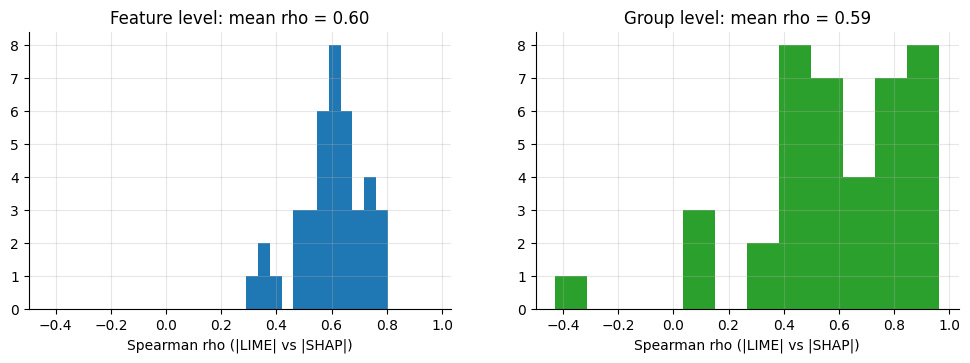

Feature level: mean rho = 0.600 (std 0.118) | Group level: mean rho = 0.590 (std 0.281)


In [25]:
# D4: LIME vs SHAP agreement on 40 random test days (non-discretised LIME, contribution = weight x standardised deviation)
rng_d4 = np.random.default_rng(SEED)
days = rng_d4.choice(len(X_test), 40, replace=False)
lime_nd = make_lime(seed=SEED, discretize=False, categorical=False)
mu_nd, sd_nd = lime_nd.scaler.mean_, lime_nd.scaler.scale_

rho_feat, rho_group = [], []
group_idx = {g: [feature_names.index(f) for f in fs] for g, fs in FEATURE_GROUPS.items()}
for i in days:
    x = X_test.values[i]
    e = lime_nd.explain_instance(x, predict_fn, num_features=n_feat, num_samples=3000)
    w = lime_weight_vector(e, n_feat)
    contrib = w * (x - mu_nd) / sd_nd              # LIME's contribution relative to the average training day
    phi = shap_exp.values[i]
    rho_feat.append(spearmanr(np.abs(contrib), np.abs(phi))[0])
    lg = np.array([contrib[ix].sum() for ix in group_idx.values()])      # sum signed contributions per group
    sg = np.array([phi[ix].sum() for ix in group_idx.values()])
    rho_group.append(spearmanr(np.abs(lg), np.abs(sg))[0])

rho_feat, rho_group = np.array(rho_feat), np.array(rho_group)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharex=True)
axes[0].hist(rho_feat, bins=12, color="tab:blue"); axes[0].set_title(f"Feature level: mean rho = {np.nanmean(rho_feat):.2f}")
axes[1].hist(rho_group, bins=12, color="tab:green"); axes[1].set_title(f"Group level: mean rho = {np.nanmean(rho_group):.2f}")
for a in axes: a.set_xlabel("Spearman rho (|LIME| vs |SHAP|)")
plt.show()
print(f"Feature level: mean rho = {np.nanmean(rho_feat):.3f} (std {np.nanstd(rho_feat):.3f}) | Group level: mean rho = {np.nanmean(rho_group):.3f} (std {np.nanstd(rho_group):.3f})")

**D4 — Your answer:**

*Write 3–6 sentences here, quoting the numbers your code produced.*

---
# Part E: A sequence model and attribution methods (15 marks)

### E1 (3 marks)
Build input windows of **W = 14** days with **six channels** per step: scaled `log1p(PM2.5)`, `DEWP`, `PRES`, `Iws`, `doy_sin`, `doy_cos`. Fit all scalers on the training years only. Train a small LSTM or 1-D CNN with early stopping on 2013, and add its test MAE (µg/m³) to the table from B3.

windows: (1811, 14, 6) | targets: (1811,)
train / val / test windows: 1081 365 365
Stopped after 23 epochs | best validation MSE (scaled) = 0.5949


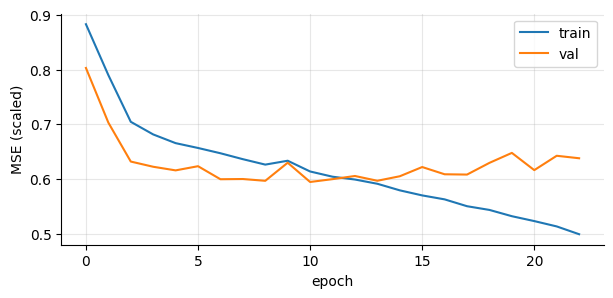

,MAE,RMSE
Persistence,52.75,75.71
7-day mean,60.59,82.76
LightGBM,45.40,67.14
LightGBM oracle (day-t weather),30.35,43.31
LSTM (14-day window),47.15,68.65


In [26]:
W = 14
CHANNELS = ["log_pm", "DEWP", "PRES", "Iws", "doy_sin", "doy_cos"]
device = torch.device("cpu")          # small model: CPU is enough (and avoids cuDNN-RNN gradient restrictions)

# --- E1: windows of W days ending at day t-1, target = day t
doy_all = np.asarray(daily_clean.index.dayofyear)
feat = pd.DataFrame({"log_pm": np.log1p(daily_clean["pm2.5"]), "DEWP": daily_clean["DEWP"], "PRES": daily_clean["PRES"],
                     "Iws": daily_clean["Iws"], "doy_sin": np.sin(2 * np.pi * doy_all / 365.25),
                     "doy_cos": np.cos(2 * np.pi * doy_all / 365.25)}, index=daily_clean.index)[CHANNELS]
vals = feat.values.astype("float32")
Xs, ys, ds = [], [], []
for i in range(W, len(feat)):
    win = vals[i - W:i]
    if np.isnan(win).any() or np.isnan(vals[i, 0]):
        continue
    Xs.append(win); ys.append(vals[i, 0]); ds.append(feat.index[i])
X_seq, y_seq, seq_dates = np.stack(Xs), np.array(ys, dtype="float32"), pd.DatetimeIndex(ds)
print("windows:", X_seq.shape, "| targets:", y_seq.shape)

# --- split by the year of the TARGET day; scalers fitted on the training years only
tr_m, va_m, te_m = seq_dates.year <= 2012, seq_dates.year == 2013, seq_dates.year == 2014
mu = feat.loc[:"2012"].mean().values.astype("float32")
sd = feat.loc[:"2012"].std(ddof=0).values.astype("float32")
Xs_all = (X_seq - mu) / sd                       # every channel standardised with TRAIN statistics
ys_all = (y_seq - mu[0]) / sd[0]                 # target = scaled log1p(PM2.5) of day t
X_tr_t, X_va_t, X_te_t = [torch.tensor(Xs_all[m]) for m in (tr_m, va_m, te_m)]
y_tr_t, y_va_t, y_te_t = [torch.tensor(ys_all[m]) for m in (tr_m, va_m, te_m)]
print("train / val / test windows:", len(X_tr_t), len(X_va_t), len(X_te_t))

class SeqForecaster(nn.Module):
    def __init__(self, n_in=len(CHANNELS), hidden=48):
        super().__init__()
        self.lstm = nn.LSTM(n_in, hidden, batch_first=True)
        self.head = nn.Sequential(nn.Dropout(0.1), nn.Linear(hidden, 1))
    def forward(self, x):          # x: (batch, W, channels)
        out, _ = self.lstm(x)
        return self.head(out[:, -1]).squeeze(-1)      # (batch,)

torch.manual_seed(SEED)
model = SeqForecaster()
opt = torch.optim.Adam(model.parameters(), lr=3e-3, weight_decay=1e-5)
loss_fn = nn.MSELoss()
gen = torch.Generator().manual_seed(SEED)
best_val, best_state, patience, bad = np.inf, None, 12, 0
hist = []
for epoch in range(120):
    model.train()
    perm = torch.randperm(len(X_tr_t), generator=gen)
    for b in range(0, len(perm), 64):
        idx = perm[b:b + 64]
        opt.zero_grad(); loss = loss_fn(model(X_tr_t[idx]), y_tr_t[idx]); loss.backward(); opt.step()
    model.eval()
    with torch.no_grad():
        tr_loss, va_loss = loss_fn(model(X_tr_t), y_tr_t).item(), loss_fn(model(X_va_t), y_va_t).item()
    hist.append((tr_loss, va_loss))
    if va_loss < best_val - 1e-5:
        best_val, bad = va_loss, 0
        best_state = {k: v.clone() for k, v in model.state_dict().items()}
    else:
        bad += 1
        if bad >= patience:
            break
model.load_state_dict(best_state); model.eval()
for p in model.parameters():
    p.requires_grad_(False)
print(f"Stopped after {epoch + 1} epochs | best validation MSE (scaled) = {best_val:.4f}")
plt.figure(figsize=(7, 3)); plt.plot(np.array(hist)); plt.legend(["train", "val"]); plt.xlabel("epoch"); plt.ylabel("MSE (scaled)"); plt.show()

# --- test MAE in µg/m³ and add to the table
with torch.no_grad():
    pred_seq = np.clip(np.expm1(model(X_te_t).numpy() * sd[0] + mu[0]), 0, None)
test_dates_seq = seq_dates[te_m]
assert (test_dates_seq == test.index).all(), "LSTM and LightGBM must be scored on the same 365 days"
results.loc["LSTM (14-day window)"] = pd.Series(metrics(y_test_raw, pred_seq)).round(2)
results

**E1 — Your answer:**

*Write 3–6 sentences here, quoting the numbers your code produced.*

### E2 (5 marks)
Implement **from scratch in PyTorch** (no Captum): Saliency, Gradient × Input, SmoothGrad and Integrated Gradients. Use the average training window as the IG baseline. Verify IG **completeness** numerically and report the mean gap. Then compute GradientSHAP with `shap.GradientExplainer` and 200 background windows.

In [27]:
# E2: attribution methods from scratch (no Captum)
BASELINE = X_tr_t.mean(dim=0, keepdim=True)          # (1, W, C): the average training window
n_te = len(X_te_t)

def _grad(x):
    """gradient of the summed model output w.r.t. the input (one backward pass for the whole batch)"""
    x = x.detach().clone().requires_grad_(True)
    g, = torch.autograd.grad(model(x).sum(), x)
    return g.detach()

def saliency(x):          return _grad(x).abs()
def grad_x_input(x):      return _grad(x) * x
def smoothgrad(x, n=30, sigma=0.15):
    gen_sg = torch.Generator().manual_seed(SEED)
    g = torch.zeros_like(x)
    for _ in range(n):
        g += _grad(x + sigma * torch.randn(x.shape, generator=gen_sg))
    return g / n
def integrated_gradients(x, baseline=BASELINE, steps=64):
    base = baseline.expand_as(x)
    total = torch.zeros_like(x)
    for k in range(steps):                                   # midpoint Riemann sum along the straight path
        total += _grad(base + ((k + 0.5) / steps) * (x - base))
    return (x - base) * total / steps

ATTR = {}
ATTR["Saliency"] = saliency(X_te_t).numpy()
ATTR["Grad x Input"] = grad_x_input(X_te_t).numpy()
ATTR["SmoothGrad"] = smoothgrad(X_te_t).numpy()
ig_te = integrated_gradients(X_te_t)
ATTR["Integrated Gradients"] = ig_te.numpy()

# completeness: sum of IG attributions = f(x) - f(baseline)
with torch.no_grad():
    f_x, f_b = model(X_te_t), model(BASELINE)
gap_ig = (ig_te.sum(dim=(1, 2)) - (f_x - f_b)).abs()
print(f"IG completeness (64 steps): mean |sum(IG) - (f(x) - f(baseline))| = {gap_ig.mean():.5f} | max = {gap_ig.max():.5f}"
      f" | mean |f(x) - f(baseline)| = {(f_x - f_b).abs().mean():.3f}")

# GradientSHAP with 200 background windows
np.random.seed(SEED); torch.manual_seed(SEED)
class _Wrap(nn.Module):
    def __init__(self, m): super().__init__(); self.m = m
    def forward(self, x): return self.m(x).unsqueeze(-1)       # shap wants (batch, n_outputs)
bg = X_tr_t[np.random.default_rng(SEED).choice(len(X_tr_t), 200, replace=False)]
grad_shap = shap.GradientExplainer(_Wrap(model), bg)
sv_g = grad_shap.shap_values(X_te_t)
sv_g = np.asarray(sv_g[0] if isinstance(sv_g, list) else sv_g).reshape(n_te, W, len(CHANNELS))
ATTR["GradientSHAP"] = sv_g
print({k: v.shape for k, v in ATTR.items()})

IG completeness (64 steps): mean |sum(IG) - (f(x) - f(baseline))| = 0.00001 | max = 0.00006 | mean |f(x) - f(baseline)| = 0.463
{'Saliency': (365, 14, 6), 'Grad x Input': (365, 14, 6), 'SmoothGrad': (365, 14, 6), 'Integrated Gradients': (365, 14, 6), 'GradientSHAP': (365, 14, 6)}


**E2 — Your answer:**

*Write 3–6 sentences here, quoting the numbers your code produced.*

### E3 (3 marks)
Implement **Occlusion** (window k = 2 days, all channels) and a **segment-based LIME** (7 segments of 2 days, baseline replacement, weighted ridge).

In [28]:
# E3: Occlusion and segment-based LIME (both give one score per time step; all channels are perturbed together)
@torch.no_grad()
def occlusion(x, k=2, baseline=BASELINE):
    base, f0 = baseline.expand_as(x), model(x)
    attr, cnt = torch.zeros(len(x), W), torch.zeros(W)
    for s in range(0, W - k + 1):                       # slide a k-day window over the history
        xo = x.clone(); xo[:, s:s + k] = base[:, s:s + k]
        attr[:, s:s + k] += ((f0 - model(xo)) / k)[:, None]    # drop in forecast when these days are removed
        cnt[s:s + k] += 1
    return (attr / cnt).numpy()

def lime_segments(x, n_seg=7, n_samples=600, kernel_width=0.35, baseline=BASELINE, seed=SEED):
    """x: (n, W, C). Returns (n, W): ridge coefficient of each 2-day segment, spread over its days."""
    rng_l = np.random.default_rng(seed)
    seg_len = W // n_seg
    Z = rng_l.integers(0, 2, size=(n_samples, n_seg)); Z[0] = 1            # 1 = keep segment, 0 = replace by baseline
    dist = 1 - Z.mean(axis=1)                                              # fraction of segments removed
    sw = np.exp(-(dist ** 2) / kernel_width ** 2)                          # proximity kernel
    keep = torch.tensor(np.repeat(Z, seg_len, axis=1), dtype=torch.float32)[:, :, None]   # (S, W, 1)
    out = np.zeros((len(x), W))
    for i in range(len(x)):
        xp = keep * x[i:i + 1] + (1 - keep) * baseline
        with torch.no_grad():
            y = model(xp).numpy()
        out[i] = np.repeat(Ridge(alpha=1.0).fit(Z, y, sample_weight=sw).coef_ / seg_len, seg_len)
    return out

ATTR["Occlusion"] = occlusion(X_te_t)
ATTR["Segment-LIME"] = lime_segments(X_te_t)
METHODS = list(ATTR)

# one score per time step (sum over channels) for every method: used in E4, F1, F2
STEP = {m: (a.sum(axis=2) if a.ndim == 3 else a) for m, a in ATTR.items()}
print({m: a.shape for m, a in STEP.items()})

{'Saliency': (365, 14), 'Grad x Input': (365, 14), 'SmoothGrad': (365, 14), 'Integrated Gradients': (365, 14), 'GradientSHAP': (365, 14), 'Occlusion': (365, 14), 'Segment-LIME': (365, 14)}


### E4 (4 marks)
For the model's largest-error test day, plot:
- (a) the 14-day input history,
- (b) a methods × time-step heatmap of attributions summed over channels, normalised per row,
- (c) an Integrated Gradients **time × channel** heatmap.

Which channel and which day drove that forecast? Does the explanation agree with the domain hints?

> **Baseline question.** The average training window means "a typical fortnight of pollution and weather." Is this a sensible baseline for pollution, given its heavy right skew and strong winter/summer difference? Propose one alternative baseline and say how it would change the meaning of the attributions.

Largest-error day: 2014-01-16 | forecast 147.3 vs actual 457.5 µg/m³ | error 310.2


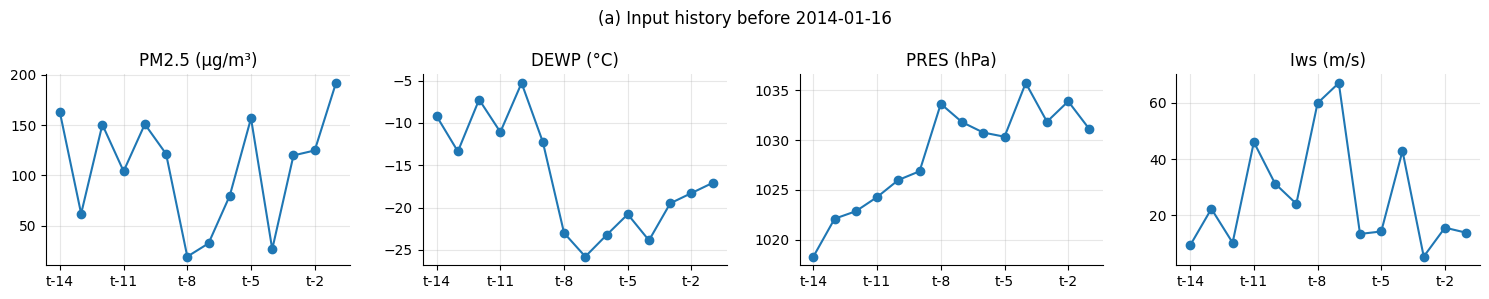

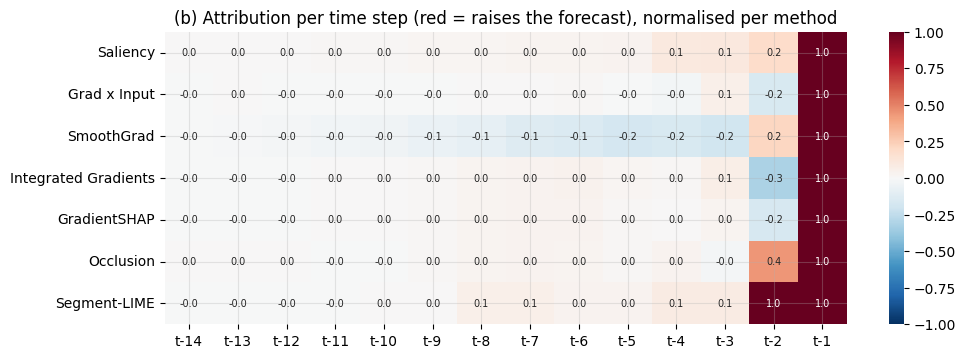

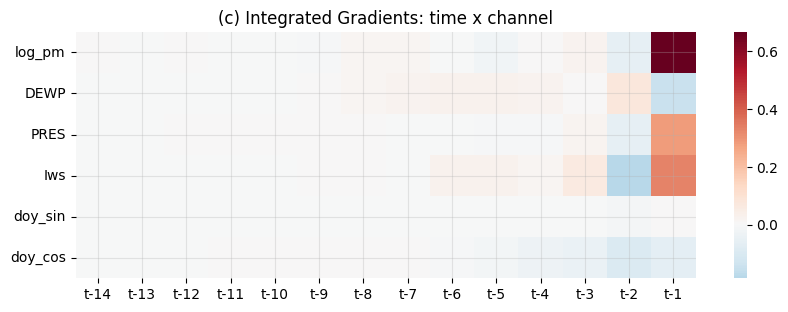

Largest |IG|: channel = log_pm, day = t-1 (value +0.665)
IG summed per channel: {'log_pm': np.float32(0.634), 'DEWP': np.float32(0.046), 'PRES': np.float32(0.244), 'Iws': np.float32(0.278), 'doy_sin': np.float32(-0.008), 'doy_cos': np.float32(-0.246)}
f(average window) = -0.080, f(clean-air window) = -0.307, f(x) = 0.869 (scaled log units)


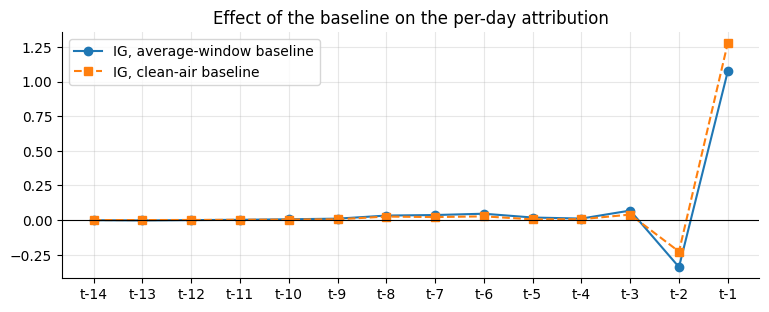

In [29]:
# E4: explain the sequence model's largest-error test day
with torch.no_grad():
    pred_seq_log = model(X_te_t).numpy() * sd[0] + mu[0]
err_seq = pd.Series(np.abs(np.expm1(pred_seq_log) - y_test_raw.values), index=test.index)
d_star = err_seq.idxmax(); j = test.index.get_loc(d_star)
print(f"Largest-error day: {d_star.date()} | forecast {np.expm1(pred_seq_log[j]):.1f} vs actual {y_test_raw.iloc[j]:.1f} µg/m³ | error {err_seq.iloc[j]:.1f}")

# (a) the 14-day input history (original units)
hist_dates = daily_clean.index[daily_clean.index.get_loc(d_star) - W: daily_clean.index.get_loc(d_star)]
raw_win = pd.DataFrame({"PM2.5 (µg/m³)": daily_clean.loc[hist_dates, "pm2.5"], "DEWP (°C)": daily_clean.loc[hist_dates, "DEWP"],
                        "PRES (hPa)": daily_clean.loc[hist_dates, "PRES"], "Iws (m/s)": daily_clean.loc[hist_dates, "Iws"]})
lags = [f"t-{W - k}" for k in range(W)]
fig, axes = plt.subplots(1, 4, figsize=(15, 3))
for ax, c in zip(axes, raw_win.columns):
    ax.plot(range(W), raw_win[c].values, "o-"); ax.set_title(c); ax.set_xticks(range(0, W, 3)); ax.set_xticklabels(lags[::3])
plt.suptitle(f"(a) Input history before {d_star.date()}"); plt.tight_layout(); plt.show()

# (b) methods x time-step heatmap (attributions summed over channels, normalised per row)
H = np.stack([STEP[m][j] / (np.abs(STEP[m][j]).max() + 1e-12) for m in METHODS])
plt.figure(figsize=(11, 3.8))
sns.heatmap(H, cmap="RdBu_r", center=0, vmin=-1, vmax=1, xticklabels=lags, yticklabels=METHODS, annot=True, fmt=".1f", annot_kws={"size": 7})
plt.title("(b) Attribution per time step (red = raises the forecast), normalised per method"); plt.show()

# (c) Integrated Gradients, time x channel
plt.figure(figsize=(10, 3.2))
ig_j = ATTR["Integrated Gradients"][j].T
sns.heatmap(ig_j, cmap="RdBu_r", center=0, xticklabels=lags, yticklabels=CHANNELS)
plt.title("(c) Integrated Gradients: time x channel"); plt.show()
t_star, c_star = np.unravel_index(np.abs(ATTR["Integrated Gradients"][j]).argmax(), (W, len(CHANNELS)))
print(f"Largest |IG|: channel = {CHANNELS[c_star]}, day = {lags[t_star]} (value {ATTR['Integrated Gradients'][j][t_star, c_star]:+.3f})")
print("IG summed per channel:", dict(zip(CHANNELS, ATTR["Integrated Gradients"][j].sum(0).round(3))))

# --- baseline question: average window vs a CLEAN-AIR baseline (mean of the cleanest 10 % of training windows)
pm_level = X_seq[tr_m][:, :, 0].mean(axis=1)
clean_idx = np.argsort(pm_level)[: max(1, int(0.1 * len(pm_level)))]
BASELINE_CLEAN = X_tr_t[clean_idx].mean(dim=0, keepdim=True)
ig_clean = integrated_gradients(X_te_t[j:j + 1], baseline=BASELINE_CLEAN)
with torch.no_grad():
    print(f"f(average window) = {model(BASELINE).item():.3f}, f(clean-air window) = {model(BASELINE_CLEAN).item():.3f}, f(x) = {model(X_te_t[j:j+1]).item():.3f} (scaled log units)")
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(lags, STEP["Integrated Gradients"][j], "o-", label="IG, average-window baseline")
ax.plot(lags, ig_clean.sum(dim=2)[0].numpy(), "s--", label="IG, clean-air baseline")
ax.axhline(0, color="k", lw=0.8); ax.legend(); ax.set_title("Effect of the baseline on the per-day attribution"); plt.show()

**E4 — Your answer:**

*Write 3–6 sentences here, quoting the numbers your code produced.*

---
# Part F: Evaluating explanations (10 marks)

### F1 (3 marks) — agreement
Compute the mean per-instance Spearman correlation between the absolute per-time-step attributions of every pair of methods from Part E. Show it as a heatmap. Which methods form clusters, and why?

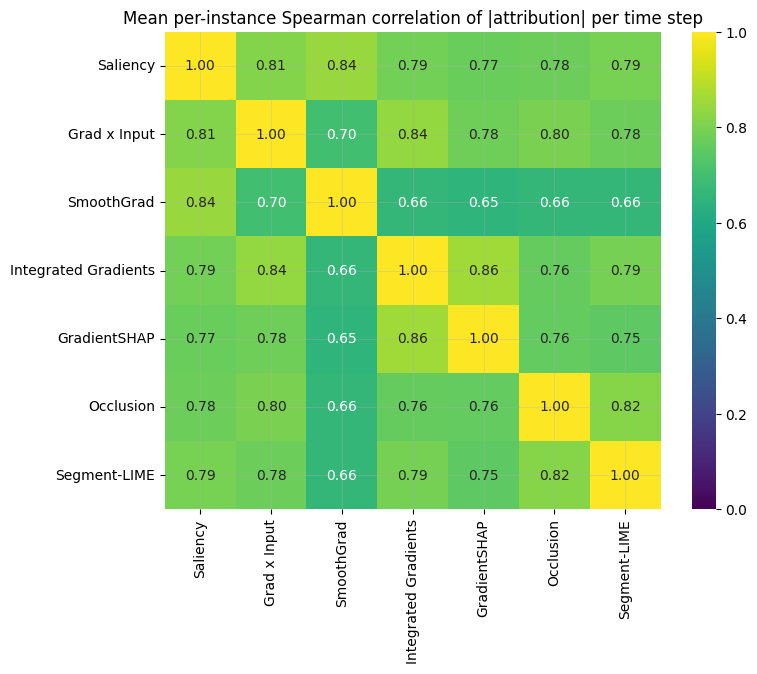

Most similar pairs:
Integrated Gradients  GradientSHAP            0.86
Saliency              SmoothGrad              0.84
Grad x Input          Integrated Gradients    0.84
Occlusion             Segment-LIME            0.82
Saliency              Grad x Input            0.81
Least similar pairs:
SmoothGrad  Integrated Gradients    0.66
            Occlusion               0.66
            Segment-LIME            0.66
            GradientSHAP            0.65


In [30]:
# F1: mean per-instance Spearman correlation between |per-step attributions|
from scipy.stats import rankdata
A = {m: np.abs(STEP[m]) for m in METHODS}
R = {m: rankdata(A[m], axis=1) for m in METHODS}

def row_corr(a, b):
    a, b = a - a.mean(1, keepdims=True), b - b.mean(1, keepdims=True)
    return (a * b).sum(1) / (np.sqrt((a ** 2).sum(1) * (b ** 2).sum(1)) + 1e-12)

agree = pd.DataFrame([[np.nanmean(row_corr(R[a], R[b])) for b in METHODS] for a in METHODS], index=METHODS, columns=METHODS)
plt.figure(figsize=(8, 6.2))
sns.heatmap(agree, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1)
plt.title("Mean per-instance Spearman correlation of |attribution| per time step"); plt.show()
pairs = agree.where(np.triu(np.ones(agree.shape, bool), 1)).stack().dropna().sort_values(ascending=False)
print("Most similar pairs:"); print(pairs.head(5).round(2).to_string())
print("Least similar pairs:"); print(pairs.tail(4).round(2).to_string())

**F1 — Your answer:**

*Write 3–6 sentences here, quoting the numbers your code produced.*

### F2 (5 marks) — faithfulness
Implement a **deletion** test (Most Relevant First) on the PM2.5 channel *and* an **insertion** test (start from the baseline and add the most relevant steps first). Include a **random** ordering as a control. Report normalised AUCs for every method in one table.

Plot the memory profile (mean |attribution| per time step over 2014, per method). Unlike the temperature model in the lecture, which had a one-day memory, does your test now separate the methods? Explain why or why not.

,Deletion AUC (higher = better),Insertion AUC (higher = better),rank (deletion),rank (insertion)
Occlusion,0.987,0.850,1,5
SmoothGrad,0.980,0.844,2,6
GradientSHAP,0.976,0.878,3,2
Grad x Input,0.969,0.865,4,4
Integrated Gradients,0.969,0.870,5,3
Saliency,0.963,0.885,6,1
Segment-LIME,0.903,0.814,7,7
Random,0.598,0.412,8,8


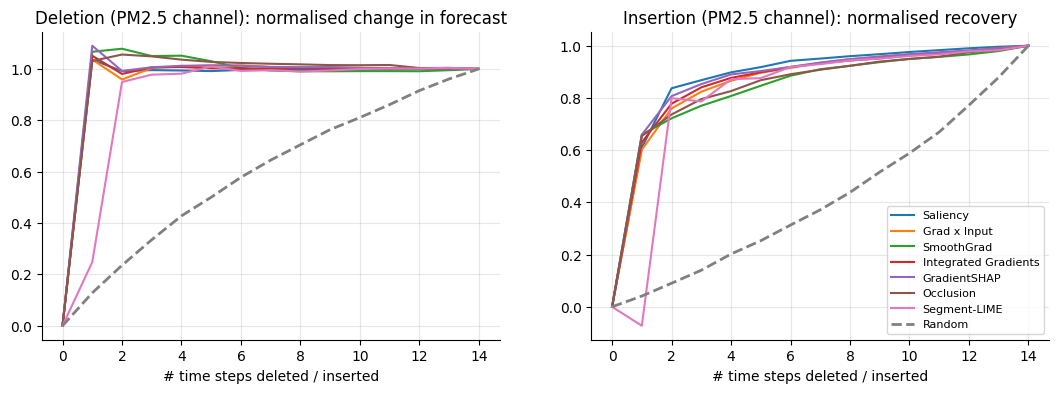

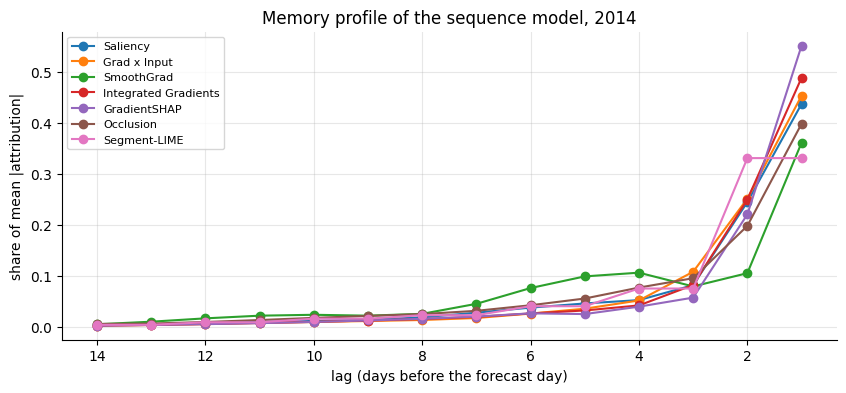

Share of attribution on the last 2 days: {'Saliency': 0.68, 'Grad x Input': 0.71, 'SmoothGrad': 0.47, 'Integrated Gradients': 0.74, 'GradientSHAP': 0.77, 'Occlusion': 0.6, 'Segment-LIME': 0.66}


In [31]:
PM_CH = [0]      # channel index of log_pm

def _channel_mask(channels):
    ch = torch.zeros(1, 1, len(CHANNELS), dtype=torch.bool); ch[..., channels] = True
    return ch

@torch.no_grad()
def deletion_curve(order, x, baseline=BASELINE, ks=range(0, W + 1), channels=PM_CH):
    """order: (n, W) time-step indices, most relevant first. Replace the first k steps of the chosen channels by the
    baseline. Returns the model outputs, shape (len(ks), n)."""
    base, ranks, ch = baseline.expand_as(x), torch.tensor(np.argsort(order, axis=1)), _channel_mask(channels)
    return np.stack([model(torch.where((ranks < k)[:, :, None] & ch, base, x)).numpy() for k in ks])

@torch.no_grad()
def insertion_curve(order, x, baseline=BASELINE, ks=range(0, W + 1), channels=PM_CH):
    """start with the chosen channels fully at baseline, then put the first k (most relevant) real steps back."""
    base, ranks, ch = baseline.expand_as(x), torch.tensor(np.argsort(order, axis=1)), _channel_mask(channels)
    return np.stack([model(torch.where((ranks >= k)[:, :, None] & ch, base, x)).numpy() for k in ks])

def auc(y):                                  # trapezoid rule on k/W in [0, 1]
    xs = np.linspace(0, 1, len(y))
    return float(np.sum((y[1:] + y[:-1]) / 2 * np.diff(xs)))

with torch.no_grad():
    f_orig = model(X_te_t).numpy()

def summarise(order):
    d = np.abs(deletion_curve(order, X_te_t) - f_orig).mean(1)          # mean |change| after deleting top-k steps
    i = np.abs(insertion_curve(order, X_te_t) - f_orig).mean(1)         # mean |remaining error| after inserting top-k steps
    d_n, rec = d / d[-1], 1 - i / i[0]                                   # normalise: deletion ends at 1, insertion starts at 0
    return d_n, rec

curves, rows = {}, {}
for m in METHODS:
    order = np.argsort(-np.abs(STEP[m]), axis=1)
    curves[m] = summarise(order)
# random control: average over 10 random orderings
rng_r = np.random.default_rng(SEED)
rand = [summarise(np.argsort(rng_r.random((n_te, W)), axis=1)) for _ in range(10)]
curves["Random"] = (np.mean([r[0] for r in rand], axis=0), np.mean([r[1] for r in rand], axis=0))

faith = pd.DataFrame({m: {"Deletion AUC (higher = better)": auc(c[0]), "Insertion AUC (higher = better)": auc(c[1])}
                      for m, c in curves.items()}).T
faith["rank (deletion)"] = faith.iloc[:, 0].rank(ascending=False).astype(int)
faith["rank (insertion)"] = faith.iloc[:, 1].rank(ascending=False).astype(int)
display(faith.sort_values("Deletion AUC (higher = better)", ascending=False).round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ks = np.arange(W + 1)
for m, (d_n, rec) in curves.items():
    st = dict(ls="--", color="grey", lw=2) if m == "Random" else {}
    axes[0].plot(ks, d_n, label=m, **st); axes[1].plot(ks, rec, label=m, **st)
axes[0].set_title("Deletion (PM2.5 channel): normalised change in forecast"); axes[1].set_title("Insertion (PM2.5 channel): normalised recovery")
for a in axes: a.set_xlabel("# time steps deleted / inserted")
axes[1].legend(fontsize=8); plt.show()

# memory profile: mean |attribution| per time step over 2014, each method normalised to sum 1
lag_axis = np.arange(W, 0, -1)               # step index 0 = 14 days ago ... step 13 = yesterday (lag 1)
plt.figure(figsize=(10, 4))
for m in METHODS:
    prof = np.abs(STEP[m]).mean(0); plt.plot(lag_axis, prof / prof.sum(), "o-", label=m)
plt.xlabel("lag (days before the forecast day)"); plt.ylabel("share of mean |attribution|"); plt.gca().invert_xaxis()
plt.title("Memory profile of the sequence model, 2014"); plt.legend(fontsize=8); plt.show()
print("Share of attribution on the last 2 days:", {m: round(float(np.abs(STEP[m]).mean(0)[-2:].sum() / np.abs(STEP[m]).mean(0).sum()), 2) for m in METHODS})

**F2 — Your answer:**

*Write 3–6 sentences here, quoting the numbers your code produced.*

### F3 (2 marks) — channel-level faithfulness
Repeat the deletion test, but delete one whole **channel** at a time, ranked by each method's total channel attribution. Do the methods agree on whether wind or humidity matters more?

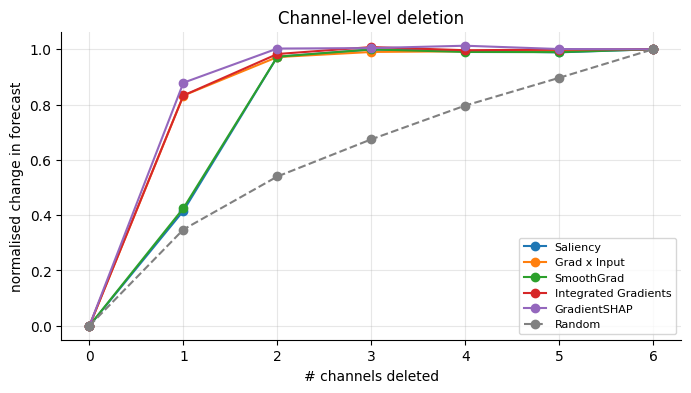

,Saliency,Grad x Input,SmoothGrad,Integrated Gradients,GradientSHAP
log_pm,0.302,0.333,0.302,0.328,0.345
DEWP,0.114,0.131,0.114,0.131,0.137
PRES,0.118,0.124,0.119,0.130,0.136
Iws,0.348,0.267,0.348,0.274,0.240
doy_sin,0.036,0.046,0.035,0.038,0.039
doy_cos,0.083,0.098,0.083,0.098,0.103


,channel-deletion AUC
Saliency,0.812
Grad x Input,0.881
SmoothGrad,0.813
Integrated Gradients,0.886
GradientSHAP,0.900
Random,0.626


Wind (Iws) vs humidity (DEWP): {'Saliency': 'wind > other', 'Grad x Input': 'wind > other', 'SmoothGrad': 'wind > other', 'Integrated Gradients': 'wind > other', 'GradientSHAP': 'wind > other'}
Most important channel per method: {'Saliency': 'Iws', 'Grad x Input': 'log_pm', 'SmoothGrad': 'Iws', 'Integrated Gradients': 'log_pm', 'GradientSHAP': 'log_pm'}


In [32]:
# F3: delete one whole CHANNEL at a time, ranked by each method's total channel attribution
# (Occlusion and Segment-LIME perturb all channels together, so they have no channel attribution and are excluded.)
CH_METHODS = ["Saliency", "Grad x Input", "SmoothGrad", "Integrated Gradients", "GradientSHAP"]

@torch.no_grad()
def channel_deletion(order_c, x, baseline=BASELINE):
    base, ranks = baseline.expand_as(x), torch.tensor(np.argsort(order_c, axis=1))
    return np.stack([model(torch.where((ranks < k)[:, None, :], base, x)).numpy() for k in range(len(CHANNELS) + 1)])

def ch_curve(order_c):
    d = np.abs(channel_deletion(order_c, X_te_t) - f_orig).mean(1)
    return d / d[-1]

ch_scores = {m: np.abs(ATTR[m]).sum(axis=1) for m in CH_METHODS}              # (n, C): total |attribution| per channel
ch_curves = {m: ch_curve(np.argsort(-ch_scores[m], axis=1)) for m in CH_METHODS}
rand_c = np.mean([ch_curve(np.argsort(rng_r.random((n_te, len(CHANNELS))), axis=1)) for _ in range(10)], axis=0)
ch_curves["Random"] = rand_c

plt.figure(figsize=(8, 4))
for m, c in ch_curves.items():
    plt.plot(range(len(CHANNELS) + 1), c, "o-", label=m, **(dict(ls="--", color="grey") if m == "Random" else {}))
plt.xlabel("# channels deleted"); plt.ylabel("normalised change in forecast"); plt.legend(fontsize=8); plt.title("Channel-level deletion"); plt.show()

share = pd.DataFrame({m: ch_scores[m].mean(0) / ch_scores[m].mean(0).sum() for m in CH_METHODS}, index=CHANNELS)
display(share.round(3))
display(pd.Series({m: auc(c) for m, c in ch_curves.items()}, name="channel-deletion AUC").round(3).to_frame())
print("Wind (Iws) vs humidity (DEWP):", {m: ("wind" if share.loc["Iws", m] > share.loc["DEWP", m] else "humidity") + " > other" for m in CH_METHODS})
print("Most important channel per method:", {m: share[m].idxmax() for m in CH_METHODS})

**F3 — Your answer:**

*Write 3–6 sentences here, quoting the numbers your code produced.*

---
# Part G: Reflection (10 marks)
Answer in prose, 150–250 words each, citing your own results.

### G1 (4 marks)
You must explain tomorrow's pollution forecast to a city health officer with no ML training. Which single explanation from this assignment would you show them, and what would you say? Which explanation would you *not* show, and why?

**G1 — Your answer:**

### G2 (3 marks)
Name the two design choices that changed your explanations the most (for example target transform, baseline, feature grouping, number of LIME samples). Give the evidence from your notebook.

**G2 — Your answer:**

### G3 (3 marks)
Propose an explanation-based **drift alarm** for this model in production. State exactly what you would compute each week and the threshold you would use, then test it by comparing 2013 with 2014.

Threshold (95th percentile of 2012->2013 weekly distance) = 0.254
Weeks above threshold: 2012->2013 = 6% (by construction ~5%) | 2013->2014 = 8%
2013->2014: mean distance 0.147 vs 0.138 | weeks in alarm (2 in a row): 0 of 52


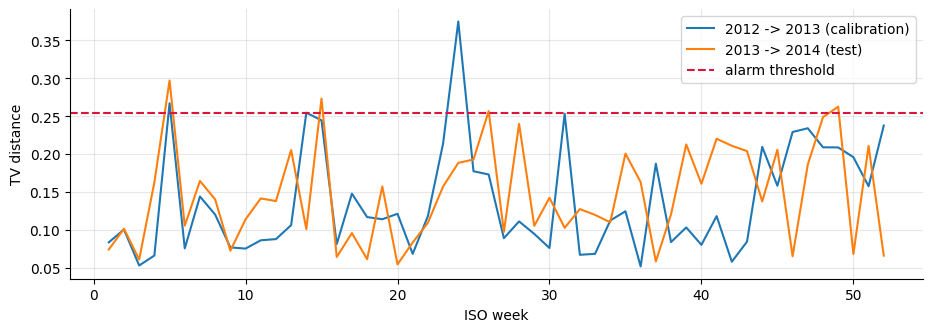

Change in the average group profile, 2014 minus 2013:
Weather yesterday      -0.034
Weather change         -0.004
Calendar               -0.000
Wind direction         -0.000
PM rolling stats        0.001
PM older lags (4-7)     0.007
PM recent lags (1-3)    0.031


In [33]:
# G3: explanation-based drift alarm.
# Weekly statistic: total-variation distance between this week's grouped-|SHAP| profile (7 groups, normalised to sum 1)
# and the profile of the SAME calendar week one year earlier.  Threshold: 95th percentile of that distance when nothing
# is known to have changed (2012 -> 2013).  Alarm = 2 consecutive weeks above the threshold.
def weekly_profiles(X_part):
    sv = tree_explainer.shap_values(X_part)
    g = grouped_shap(sv, feature_names, X_part.index).abs()
    wk = np.minimum(np.asarray(X_part.index.isocalendar().week), 52)
    prof = g.groupby(wk).mean()
    return prof.div(prof.sum(axis=1), axis=0)

P12, P13, P14 = weekly_profiles(train.loc["2012"][feature_names]), weekly_profiles(X_val), weekly_profiles(X_test)
def tv(a, b):
    common = a.index.intersection(b.index)
    return 0.5 * (a.loc[common] - b.loc[common]).abs().sum(axis=1)

d_ref, d_new = tv(P13, P12), tv(P14, P13)                      # 2012->2013 (calibration), 2013->2014 (test)
thr = d_ref.quantile(0.95)
flag = (d_new > thr)
alarm = flag & (flag.shift(1, fill_value=False) | flag.shift(-1, fill_value=False))
print(f"Threshold (95th percentile of 2012->2013 weekly distance) = {thr:.3f}")
print(f"Weeks above threshold: 2012->2013 = {(d_ref > thr).mean():.0%} (by construction ~5%) | 2013->2014 = {flag.mean():.0%}")
print(f"2013->2014: mean distance {d_new.mean():.3f} vs {d_ref.mean():.3f} | weeks in alarm (2 in a row): {int(alarm.sum())} of {len(d_new)}")
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(d_ref.index, d_ref.values, label="2012 -> 2013 (calibration)"); ax.plot(d_new.index, d_new.values, label="2013 -> 2014 (test)")
ax.axhline(thr, color="crimson", ls="--", label="alarm threshold"); ax.set_xlabel("ISO week"); ax.set_ylabel("TV distance"); ax.legend(); plt.show()
group_shift = (P14.mean() - P13.mean()).sort_values()
print("Change in the average group profile, 2014 minus 2013:"); print(group_shift.round(3).to_string())

**G3 — Your answer:**

---
# Bonus (up to 10 marks): pick up to two

- **Multi-horizon (5).** Forecast PM2.5 at t+1, t+3 and t+7 with three LightGBMs. Show how grouped SHAP shifts from lags to calendar and weather as the horizon grows.
- **TimeSHAP-style pruning (5).** For the sequence model, group all time steps older than *k* days into one "past" coalition and compute KernelSHAP on the reduced input. Find the smallest *k* that keeps 90% of the attribution.
- **Counterfactual (5).** For the most polluted test day, find the smallest change in yesterday's wind speed and direction that brings the forecast below 75 µg/m³ (China's 24-hour PM2.5 standard). Is the counterfactual physically plausible?

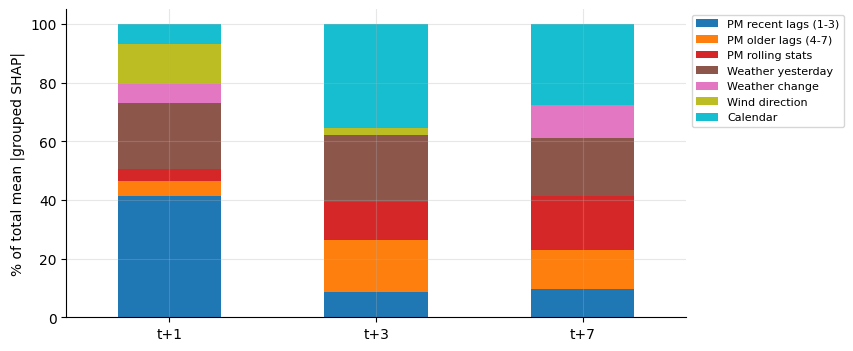

,t+1,t+3,t+7
PM recent lags (1-3),41.2,8.6,9.7
PM older lags (4-7),5.1,17.9,13.2
PM rolling stats,4.1,12.8,18.3
Weather yesterday,22.5,22.8,19.8
Weather change,6.8,0.0,11.3
Wind direction,13.5,2.6,0.0
Calendar,6.8,35.3,27.7


Test MAE (µg/m³): {'t+1': 45.4, 't+3': 56.7, 't+7': 56.8}
Most polluted forecast 2014-10-11: 238.2 µg/m³ | Iws_lag_1 = 11.6 | observed training max of Iws_lag_1 = 586


,wind direction,lowest forecast reachable (µg/m³),smallest Iws_lag_1 giving < 75
0,NW,117.7,none within observed range
1,NE,149.1,none within observed range
2,SE,157.7,none within observed range
3,cv,149.1,none within observed range


In [34]:
# ---------- Bonus 1: multi-horizon forecasts (t+1, t+3, t+7) and how grouped SHAP shifts ----------
# horizon h means: forecast the day h-1 days after the usual target day, still using only information up to day t-1
rows, shares, maes = [], {}, {}
for h in (1, 3, 7):
    tgt = data["target"].shift(-(h - 1)).rename("t")
    d = pd.concat([data[feature_names], tgt], axis=1).dropna()
    tr_h, va_h, te_h = d.loc["2010":"2012"], d.loc["2013"], d.loc["2014"]
    m_h = lgb.LGBMRegressor(n_estimators=2000, learning_rate=0.02, random_state=SEED, verbose=-1)
    m_h.fit(tr_h[feature_names], tr_h["t"], eval_set=[(va_h[feature_names], va_h["t"])], callbacks=[lgb.early_stopping(100, verbose=False)])
    raw_h = daily_clean["pm2.5"].shift(-(h - 1)).loc[te_h.index]
    maes[f"t+{h}"] = metrics(raw_h, inv(m_h.predict(te_h[feature_names])))["MAE"]
    g = grouped_shap(shap.TreeExplainer(m_h).shap_values(te_h[feature_names]), feature_names, te_h.index).abs().mean()
    shares[f"t+{h}"] = g / g.sum() * 100
shares = pd.DataFrame(shares)
shares.T.plot.bar(stacked=True, figsize=(8, 4), colormap="tab10"); plt.ylabel("% of total mean |grouped SHAP|"); plt.legend(bbox_to_anchor=(1, 1), fontsize=8); plt.xticks(rotation=0); plt.show()
display(shares.round(1)); print("Test MAE (µg/m³):", {k: round(v, 1) for k, v in maes.items()})

# ---------- Bonus 2: counterfactual wind for the most polluted forecast ----------
x_cf = X_test.loc[idx_high].copy()
base_fc = float(inv(lgbm.predict(x_cf.values.reshape(1, -1))[0]))
iws_max = X_train["Iws_lag_1"].max()
print(f"Most polluted forecast {idx_high.date()}: {base_fc:.1f} µg/m³ | Iws_lag_1 = {x_cf['Iws_lag_1']:.1f} | observed training max of Iws_lag_1 = {iws_max:.0f}")
speeds = np.linspace(0, iws_max, 400)
cf_rows = []
for dname in WIND_DIRS:
    grid = pd.DataFrame([x_cf.values] * len(speeds), columns=feature_names)
    grid["Iws_lag_1"] = speeds
    for dd in WIND_DIRS:
        grid[f"wd_{dd}"] = float(dd == dname)
    fc = inv(lgbm.predict(grid))
    ok = np.where(fc < 75)[0]
    cf_rows.append({"wind direction": dname, "lowest forecast reachable (µg/m³)": round(float(fc.min()), 1),
                    "smallest Iws_lag_1 giving < 75": (round(float(speeds[ok[0]]), 1) if len(ok) else "none within observed range")})
display(pd.DataFrame(cf_rows))

---
### Declaration
I confirm this notebook is my own work. AI assistants used (if any) and what for:

*...*